# Comparison: LRA: Phase 2 DestinE data t2m: Data Analysis

### Why this notebook matters

This notebook demonstrates scalable, Dask-backed multi-model evaluation of 2m temperature trends and variability against ERA5, using HEALPix-aware regridding for consistent gridpoint comparison.

**Purpose** - Evaluate 2 m air temperature in the LRA Phase 2 models (IFS-FESOM, IFS-NEMO, ICON) against ERA5: global-mean time series, decadal trend maps, model-minus-ERA5 trend differences, detrended variability (standard deviation), seasonal-cycle removal, and zonal-mean diagnostics.

**Required input data** - Monthly `2t` NetCDF files (r100) under `{LRA_ROOT}`; ERA5 2 m temperature (`{ERA5_DIR}`); derived trend/variability files are read from and written to `{EVA_DIR}` (originally on DKRZ Levante; not included in this repository).

**Expected outputs** - Trend and variability NetCDF files in `{EVA_DIR}`; global maps, difference maps, and zonal statistics figures embedded below.

## Key techniques demonstrated

- xarray for NetCDF I/O
- HEALPix-aware regridding (astropy_healpix)
- scipy trend statistics
- Cartopy global mapping
- ERA5 reanalysis benchmarking

In [ ]:
# --- Data location placeholders ---------------------------------------------
# The original analysis ran on DKRZ Levante. Input data are NOT included in
# this repository. Set these paths to your own data copies before running:
#
# LRA_ROOT : Destination Earth LRA Phase 2 data root
#            (subfolders: climatedt-o25.1/<MODEL>/historical-*/r100/monthly/)
# EVA_DIR  : working directory for derived NetCDF files (trends, variability)
# ERA5_DIR : ERA5 reanalysis 2 m temperature (regular lat/lon grid)
# MN5_DIR  : auxiliary HEALPix test data (only used in the quick-look section)

LRA_ROOT = "/path/to/DestinE/LRA_phase2"  # <-- EDIT before running
EVA_DIR  = "/path/to/EVA_Models"          # <-- EDIT before running
ERA5_DIR = "/path/to/ERA5"                # <-- EDIT before running
MN5_DIR  = "/path/to/MN5"                 # <-- EDIT (optional section only)

## Installation & loading packages

In [ ]:

import xarray as xr


In [ ]:
import sys
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

import cartopy.crs as ccrs
import cartopy.feature as cfeature

from astropy_healpix import HEALPix
import astropy.units as u

print('python:', sys.version)

# --- Input ---
path_nc = f"{MN5_DIR}/projt319/a3be_netcdf/sfc_mean2t/sfc_mean2t_1990.nc"
out_png = f"{MN5_DIR}/projt319/a3be_netcdf/sfc_mean2t_figures/sfc_mean2t_1990_Jan_robinson_250_315.png"

# --- Read January (time index 0) ---
# The file has dims: time(12), height(1), gsize(npix)
ds = xr.open_dataset(path_nc)
vals_hp = ds["mean2t"].isel(time=0, height=0).values.astype("float64")
npix = vals_hp.size
nside = int(round(np.sqrt(npix / 12.0)))
if 12 * nside * nside != npix:
    raise ValueError(f"npix={npix} is not 12*nside^2")

# --- HEALPix NESTED -> regular lon/lat grid (nearest-neighbor sampling) ---
# Choose a reasonably fine target grid. 1° is usually sufficient for quick-look plots.
lon = np.arange(-180.0, 180.0, 1.0)
lat = np.arange(-90.0, 90.0 + 1.0, 1.0)
lon2d, lat2d = np.meshgrid(lon, lat)

hp = HEALPix(nside=nside, order="nested", frame=None)
idx = hp.lonlat_to_healpix(lon2d * u.deg, lat2d * u.deg)

# idx has shape (lat, lon)
grid_vals = vals_hp[idx]

# --- Plot Robinson projection (matching your style) ---
fig = plt.figure(figsize=(13, 6))
ax = plt.axes(projection=ccrs.Robinson())

im = ax.pcolormesh(
    lon2d,
    lat2d,
    grid_vals,
    transform=ccrs.PlateCarree(),
    cmap="RdBu_r",
    vmin=250,
    vmax=315,
    shading="auto",
)

ax.coastlines(linewidth=0.7)
ax.add_feature(cfeature.BORDERS, linewidth=0.4, color="gray", alpha=0.2)
ax.gridlines(draw_labels=False, linewidth=0.3, color="gray", alpha=0.5)

cb = plt.colorbar(im, orientation="horizontal", pad=0.05, fraction=0.05)
cb.set_label("mean2t (K)", fontsize=10)

plt.title("mean2t (2m air temperature) — January 1990 (HEALPix NESTED → 1° grid)", fontsize=12)
plt.tight_layout()
plt.savefig(out_png, dpi=200)
plt.show()

print("saved:", out_png)


## sfc variables: t2m: 2days simulation: check

In [ ]:
# @ Levante
path_2t = f"{LRA_ROOT}/climatedt-o25.1/IFS-FESOM/historical-1990/r100/monthly/2t_o00i_r100_monthly_1990.nc"
ds_chk = xr.open_dataset(path_2t)

In [ ]:
print(list(ds_chk.data_vars))
print(list(ds_chk.coords))
print(ds_chk.dims)
print(ds_chk.sizes)

In [ ]:
print(ds_chk["2t"].attrs)

In [ ]:
print(ds_chk["2t"].dtype)
print(ds_chk["2t"].shape)

In [ ]:
from netCDF4 import Dataset

nc = Dataset(path_2t)
print(nc)

In [ ]:
import glob

files = sorted(glob.glob(
    f"{LRA_ROOT}/climatedt-o25.1/IFS-FESOM/"
    "historical-*/r100/monthly/2t_o00i_r100_monthly_*.nc"
))

files

In [ ]:
import xarray as xr
# Open all files with xarray
ds_all = xr.open_mfdataset(
    files,
    combine="by_coords"
)
ds_all

In [ ]:
# Compute area-weighted global mean time series

import numpy as np

t2m = ds_all["2t"].where(ds_all["2t"] < 9000)

weights = np.cos(np.deg2rad(t2m.lat))
weights.name = "weights"

global_mean = t2m.weighted(weights).mean(dim=("lat", "lon"))

global_mean

In [ ]:
# Convert to °C and plot the global mean time series

import matplotlib.pyplot as plt

global_mean_c = global_mean - 273.15
global_mean_c.attrs["units"] = "°C"
global_mean_c.attrs["long_name"] = "Global mean 2m air temperature"

plt.figure()
global_mean_c.plot()
plt.title("Global Mean 2m Air Temperature (1990–2014)")
plt.ylabel("Temperature (°C)")
plt.xlabel("Time")
plt.grid(True)
plt.show()

# 2m temerature: 1990-2014: 3 models

In [1]:
import glob
import xarray as xr

import numpy as np
import matplotlib.pyplot as plt


In [2]:
# Collect files for ALL THREE MODELS (1990–2014)

In [3]:

# IFS-FESOM
files_fesom = sorted(glob.glob(
    f"{LRA_ROOT}/climatedt-o25.1/"
    "IFS-FESOM/historical-*/r100/monthly/2t_o00i_r100_monthly_*.nc"
))

# IFS-NEMO
files_nemo = sorted(glob.glob(
    f"{LRA_ROOT}/climatedt-o25.1/"
    "IFS-NEMO/historical-*/r100/monthly/2t_o007_r100_monthly_*.nc"
))

# ICON
files_icon = sorted(glob.glob(
    f"{LRA_ROOT}/climatedt-o25.1/"
    "ICON/historical-*/r100/monthly/2t_o00k_r100_monthly_*.nc"
))

len(files_fesom), len(files_nemo), len(files_icon)

(25, 25, 25)

In [4]:
# #  Open all three datasets (lazy, consistent)

ds_fesom = xr.open_mfdataset(
    files_fesom,
    combine="by_coords"
)

ds_nemo = xr.open_mfdataset(
    files_nemo,
    combine="by_coords"
)

ds_icon = xr.open_mfdataset(
    files_icon,
    combine="by_coords"
)

ds_fesom, ds_nemo, ds_icon

(<xarray.Dataset>
 Dimensions:  (time: 300, lat: 180, lon: 360)
 Coordinates:
   * time     (time) datetime64[ns] 1990-01-01 1990-02-01 ... 2014-12-01
   * lat      (lat) float64 -89.5 -88.5 -87.5 -86.5 -85.5 ... 86.5 87.5 88.5 89.5
   * lon      (lon) float64 0.0 1.0 2.0 3.0 4.0 ... 355.0 356.0 357.0 358.0 359.0
 Data variables:
     2t       (time, lat, lon) float64 dask.array<chunksize=(12, 180, 360), meta=np.ndarray>,
 <xarray.Dataset>
 Dimensions:  (time: 300, lat: 180, lon: 360)
 Coordinates:
   * time     (time) datetime64[ns] 1990-01-01 1990-02-01 ... 2014-12-01
   * lat      (lat) float64 -89.5 -88.5 -87.5 -86.5 -85.5 ... 86.5 87.5 88.5 89.5
   * lon      (lon) float64 0.0 1.0 2.0 3.0 4.0 ... 355.0 356.0 357.0 358.0 359.0
 Data variables:
     2t       (time, lat, lon) float64 dask.array<chunksize=(12, 180, 360), meta=np.ndarray>,
 <xarray.Dataset>
 Dimensions:  (time: 300, lat: 180, lon: 360)
 Coordinates:
   * time     (time) datetime64[ns] 1990-01-01 1990-02-01 ... 2014-12-

In [5]:
# Global mean time series (area-weighted)

# FESOM
t2m_fesom = ds_fesom["2t"].where(ds_fesom["2t"] < 9000)
weights = np.cos(np.deg2rad(t2m_fesom.lat))
weights.name = "weights"
global_mean_fesom = t2m_fesom.weighted(weights).mean(dim=("lat", "lon"))

# NEMO
t2m_nemo = ds_nemo["2t"].where(ds_nemo["2t"] < 9000)
global_mean_nemo = t2m_nemo.weighted(weights).mean(dim=("lat", "lon"))

# ICON
t2m_icon = ds_icon["2t"].where(ds_icon["2t"] < 9000)
global_mean_icon = t2m_icon.weighted(weights).mean(dim=("lat", "lon"))

global_mean_fesom, global_mean_nemo, global_mean_icon

(<xarray.DataArray '2t' (time: 300)>
 dask.array<truediv, shape=(300,), dtype=float64, chunksize=(12,), chunktype=numpy.ndarray>
 Coordinates:
   * time     (time) datetime64[ns] 1990-01-01 1990-02-01 ... 2014-12-01,
 <xarray.DataArray '2t' (time: 300)>
 dask.array<truediv, shape=(300,), dtype=float64, chunksize=(12,), chunktype=numpy.ndarray>
 Coordinates:
   * time     (time) datetime64[ns] 1990-01-01 1990-02-01 ... 2014-12-01,
 <xarray.DataArray '2t' (time: 300)>
 dask.array<truediv, shape=(300,), dtype=float64, chunksize=(12,), chunktype=numpy.ndarray>
 Coordinates:
   * time     (time) datetime64[ns] 1990-01-01 1990-02-01 ... 2014-12-01)

In [6]:

# Convert to °C
global_mean_fesom_c = global_mean_fesom - 273.15
global_mean_fesom_c.attrs["units"] = "°C"

global_mean_nemo_c = global_mean_nemo - 273.15
global_mean_nemo_c.attrs["units"] = "°C"

global_mean_icon_c = global_mean_icon - 273.15
global_mean_icon_c.attrs["units"] = "°C"



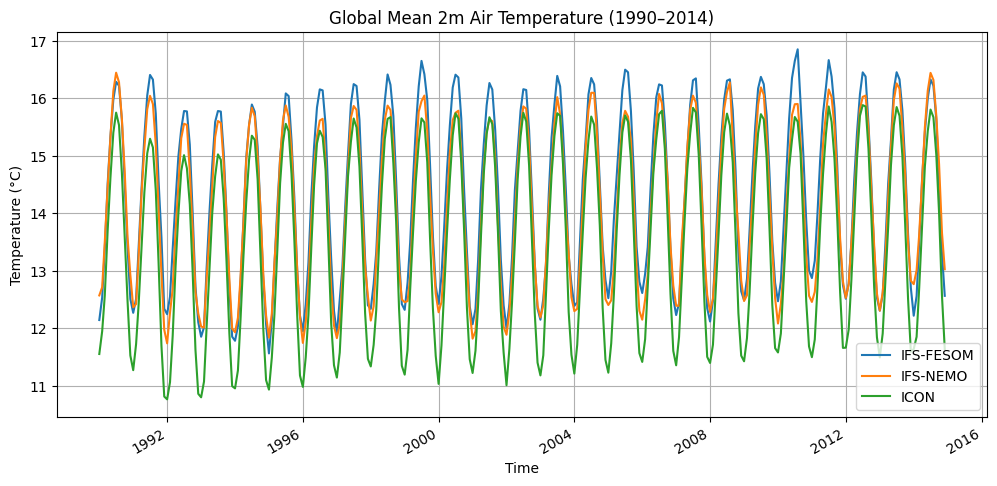

In [7]:
# Plot
plt.figure(figsize=(12,5))
global_mean_fesom_c.plot(label="IFS-FESOM")
global_mean_nemo_c.plot(label="IFS-NEMO")
global_mean_icon_c.plot(label="ICON")
plt.title("Global Mean 2m Air Temperature (1990–2014)")
plt.ylabel("Temperature (°C)")
plt.xlabel("Time")
plt.grid(True)
plt.legend()
plt.show()

## Compare with ERA

In [8]:
dset = xr.open_dataset(f'{ERA5_DIR}/t2m_ERA5_1940-2024_st_r1440x721.nc')

dset.coords['lon'] = (dset.coords['lon'] + 180) % 360 - 180
dset = dset.sortby(dset.lon)

data_era_2t= dset['var167'] - 273.15
data_era_2t

<xarray.DataArray 'var167' (time: 1020, lat: 721, lon: 1440)>
array([[[-29.721664 , -29.719711 , -29.719711 , ..., -29.723618 ,
         -29.723618 , -29.721664 ],
        [-29.75682  , -29.754868 , -29.754868 , ..., -29.760727 ,
         -29.760727 , -29.758774 ],
        [-30.022446 , -30.01854  , -30.014633 , ..., -30.034164 ,
         -30.030258 , -30.026352 ],
        ...,
        [-25.497055 , -25.497055 , -25.495102 , ..., -25.500961 ,
         -25.499008 , -25.499008 ],
        [-25.479477 , -25.479477 , -25.477524 , ..., -25.48143  ,
         -25.479477 , -25.479477 ],
        [-25.477524 , -25.47557  , -25.47557  , ..., -25.477524 ,
         -25.477524 , -25.477524 ]],

       [[-40.114563 , -40.114563 , -40.11261  , ..., -40.11847  ,
         -40.116516 , -40.116516 ],
        [-40.065735 , -40.06378  , -40.06378  , ..., -40.071594 ,
         -40.06964  , -40.067688 ],
        [-39.708313 , -39.704407 , -39.7005   , ..., -39.72003  ,
         -39.716125 , -39.71222  ],
...
        [-16.449371 , -16.449371 , -16.447418 , ..., -16.453278 ,
         -16.451324 , -16.451324 ],
        [-16.300934 , -16.29898  , -16.29898  , ..., -16.300934 ,
         -16.300934 , -16.300934 ],
        [-16.295074 , -16.295074 , -16.295074 , ..., -16.295074 ,
         -16.295074 , -16.295074 ]],

       [[-28.624115 , -28.624115 , -28.624115 , ..., -28.624115 ,
         -28.624115 , -28.624115 ],
        [-28.600677 , -28.600677 , -28.598724 , ..., -28.606537 ,
         -28.604584 , -28.60263  ],
        [-28.91513  , -28.911224 , -28.909271 , ..., -28.92685  ,
         -28.922943 , -28.919037 ],
        ...,
        [-22.797943 , -22.799896 , -22.80185  , ..., -22.794037 ,
         -22.794037 , -22.79599  ],
        [-22.731537 , -22.73349  , -22.73349  , ..., -22.729584 ,
         -22.731537 , -22.731537 ],
        [-22.653412 , -22.653412 , -22.653412 , ..., -22.653412 ,
         -22.653412 , -22.653412 ]]], dtype=float32)
Coordinates:
  * time     (time) datetime64[ns] 1940-01-01T12:00:00 ... 2024-12-01
  * lon      (lon) float64 -180.0 -179.8 -179.5 -179.2 ... 179.2 179.5 179.8
  * lat      (lat) float64 -90.0 -89.75 -89.5 -89.25 ... 89.25 89.5 89.75 90.0

In [9]:
import numpy as np

# Area weights (cosine of latitude)
weights_era = np.cos(np.deg2rad(data_era_2t.lat))
weights_era.name = "weights"

#Each latitude is weighted according to area
#Required because ERA5 grid is regular lat-lon, but not equal area
#Needed for true global mean

In [10]:
# Compute ERA5 global mean
# Mask missing values if any (ERA5 usually uses NaN for missing)
data_era_2t_masked = data_era_2t.where(np.isfinite(data_era_2t))

# Compute area-weighted global mean
global_mean_era = data_era_2t_masked.weighted(weights_era).mean(dim=("lat", "lon"))

global_mean_era

<xarray.DataArray 'var167' (time: 1020)>
array([11.4966708 , 11.87216186, 12.52402921, ..., 15.24526696,
       14.09847704, 13.42388301])
Coordinates:
  * time     (time) datetime64[ns] 1940-01-01T12:00:00 ... 2024-12-01

In [11]:
# Slice ERA5 for 1990–2014
# Select ERA5 time period 1990-01 to 2014-12
global_mean_era_sel = global_mean_era.sel(time=slice("1990-01-01", "2014-12-31"))

global_mean_era_sel

<xarray.DataArray 'var167' (time: 300)>
array([12.21199659, 12.45463557, 13.48195856, 14.30927752, 15.24503566,
       15.79847098, 16.15154775, 15.94564596, 15.21583561, 14.28818754,
       13.25006125, 12.51607003, 12.27624984, 12.60698749, 13.15624721,
       14.23899558, 15.08491417, 16.0107674 , 16.18181148, 15.97199922,
       15.24451991, 14.09814768, 13.01232808, 12.32857056, 12.23180601,
       12.4788981 , 13.16206335, 13.94215929, 14.92299989, 15.66019561,
       15.76776077, 15.62345801, 14.83730423, 13.84502626, 12.75277275,
       12.20229339, 12.13440457, 12.42110764, 13.0454535 , 14.03575945,
       14.96641528, 15.68026229, 15.87903904, 15.72717007, 14.92974341,
       14.01623916, 12.8280481 , 12.31272663, 12.04641094, 12.09332044,
       12.99071859, 14.08121272, 14.91318402, 15.7288751 , 15.95432943,
       15.72723816, 15.20770634, 14.15440466, 13.12116836, 12.39359378,
       12.31298433, 12.79498376, 13.17341251, 14.24238967, 15.02647017,
       15.89680007, 16.12505074, 16.00467702, 15.24576305, 14.25152723,
       13.14633341, 12.32507917, 12.08251898, 12.50753189, 13.09877764,
       14.01724813, 14.89442175, 15.66707339, 16.02259144, 16.00002427,
       15.1188115 , 14.00613372, 13.15101803, 12.41959225, 12.07273087,
       12.41520131, 13.23890852, 14.03376563, 15.00926163, 15.90286775,
       16.05691131, 15.97756457, 15.38174007, 14.39357858, 13.35231394,
       12.61772545, 12.39410563, 12.88379046, 13.37382595, 14.48257126,
...
       15.49448813, 14.58434106, 13.47160239, 12.86083238, 12.80527892,
       12.81764321, 13.40993565, 14.53542814, 15.34544662, 15.95912004,
       16.23529651, 16.09280237, 15.35654755, 14.43240918, 13.33182461,
       12.57629113, 12.11400237, 12.40881513, 13.4279741 , 14.23499644,
       15.1564079 , 15.78450088, 16.20549857, 16.03256388, 15.41630626,
       14.48351212, 13.42204645, 12.62163842, 12.50177405, 12.69491241,
       13.28803137, 14.30162995, 15.25757659, 15.98730102, 16.36660478,
       16.15674549, 15.55010787, 14.52640594, 13.51147296, 12.73363567,
       12.63575212, 12.95176312, 13.67814225, 14.61405237, 15.45994277,
       16.06942618, 16.28085962, 16.15762858, 15.54539219, 14.56282197,
       13.50429803, 12.56378827, 12.3516553 , 12.55363425, 13.35060745,
       14.3753072 , 15.21986278, 16.00331389, 16.37196729, 16.22227558,
       15.4937228 , 14.47596799, 13.27593257, 12.6276003 , 12.27654001,
       12.55064367, 13.2729557 , 14.41598655, 15.43512655, 16.10230012,
       16.26917524, 16.18791185, 15.55922341, 14.66553442, 13.56646265,
       12.63341512, 12.58887387, 12.74525569, 13.43311613, 14.32521701,
       15.28301042, 16.0903077 , 16.20386892, 16.16613738, 15.61600284,
       14.49777847, 13.52021957, 12.79217258, 12.56906976, 12.6338143 ,
       13.49976355, 14.47119056, 15.44492472, 16.05497355, 16.29463339,
       16.24737259, 15.63075844, 14.60993689, 13.42167975, 12.85368788])
Coordinates:
  * time     (time) datetime64[ns] 1990-01-01T12:00:00 ... 2014-12-01T12:00:00

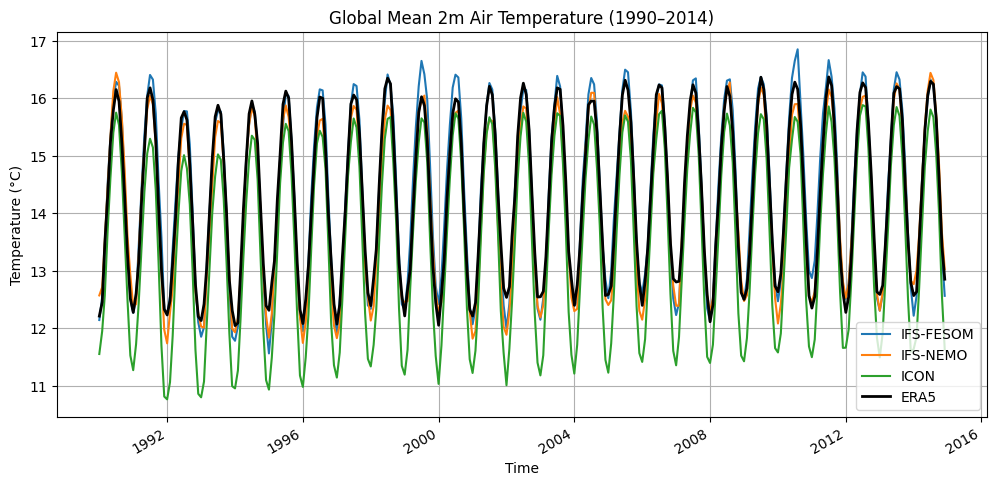

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

# Plot the three models
global_mean_fesom_c.plot(label="IFS-FESOM")
global_mean_nemo_c.plot(label="IFS-NEMO")
global_mean_icon_c.plot(label="ICON")

# Plot ERA5
global_mean_era_sel.plot(label="ERA5", color="k", linewidth=2)

plt.title("Global Mean 2m Air Temperature (1990–2014)")
plt.ylabel("Temperature (°C)")
plt.xlabel("Time")
plt.grid(True)
plt.legend()
plt.show()

## Compute annual means

In [13]:
# Compute annual means

# Annual mean for the three models
annual_mean_fesom = global_mean_fesom_c.resample(time="YS").mean()
annual_mean_nemo  = global_mean_nemo_c.resample(time="YS").mean()
annual_mean_icon  = global_mean_icon_c.resample(time="YS").mean()

# Annual mean for ERA5 (already selected 1990–2014)
annual_mean_era   = global_mean_era_sel.resample(time="YS").mean()

annual_mean_fesom, annual_mean_nemo, annual_mean_icon, annual_mean_era

(<xarray.DataArray '2t' (time: 25)>
 dask.array<stack, shape=(25,), dtype=float64, chunksize=(1,), chunktype=numpy.ndarray>
 Coordinates:
   * time     (time) datetime64[ns] 1990-01-01 1991-01-01 ... 2014-01-01
 Attributes:
     units:    °C,
 <xarray.DataArray '2t' (time: 25)>
 dask.array<stack, shape=(25,), dtype=float64, chunksize=(1,), chunktype=numpy.ndarray>
 Coordinates:
   * time     (time) datetime64[ns] 1990-01-01 1991-01-01 ... 2014-01-01
 Attributes:
     units:    °C,
 <xarray.DataArray '2t' (time: 25)>
 dask.array<stack, shape=(25,), dtype=float64, chunksize=(1,), chunktype=numpy.ndarray>
 Coordinates:
   * time     (time) datetime64[ns] 1990-01-01 1991-01-01 ... 2014-01-01
 Attributes:
     units:    °C,
 <xarray.DataArray 'var167' (time: 25)>
 array([14.23906025, 14.18429489, 13.95222814, 13.99803076, 14.03434688,
        14.21212259, 14.08214525, 14.2043808 , 14.39300647, 14.12413331,
        14.11907215, 14.27908717, 14.37575325, 14.36279783, 14.30145334,
        14.4

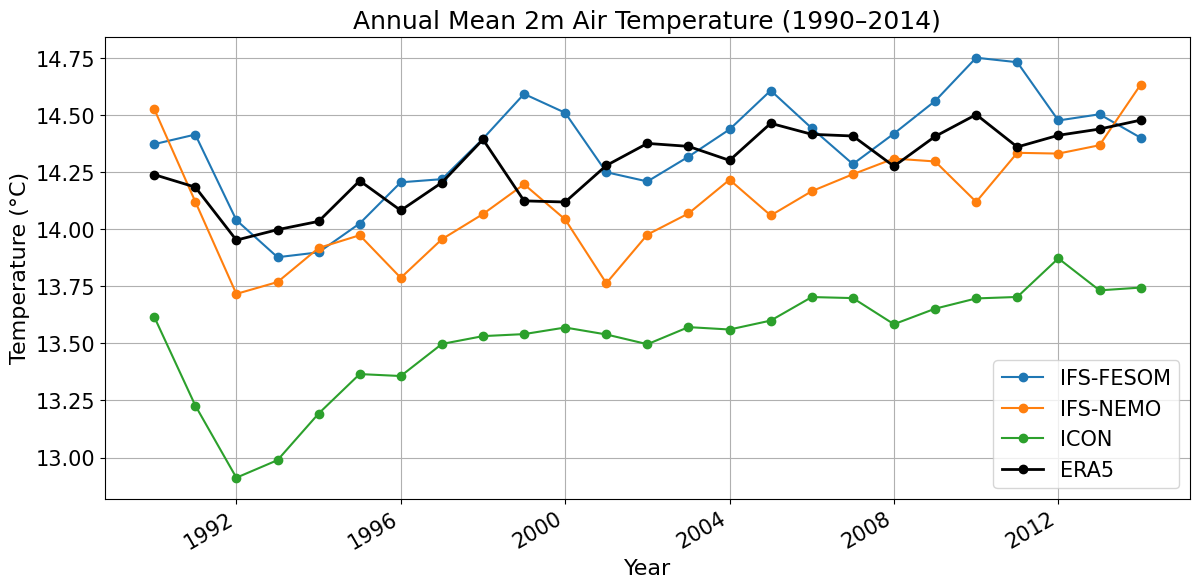

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14,6))

# Plot annual means
annual_mean_fesom.plot(marker="o", label="IFS-FESOM")
annual_mean_nemo.plot(marker="o", label="IFS-NEMO")
annual_mean_icon.plot(marker="o", label="ICON")
annual_mean_era.plot(marker="o", color="k", label="ERA5", linewidth=2)

plt.title("Annual Mean 2m Air Temperature (1990–2014)", fontsize=18)
plt.xlabel("Year", fontsize=16)
plt.ylabel("Temperature (°C)", fontsize=16)
plt.xticks(fontsize=15)
plt.yticks(fontsize=15)
plt.grid(True)
plt.legend(fontsize=15)
plt.show()

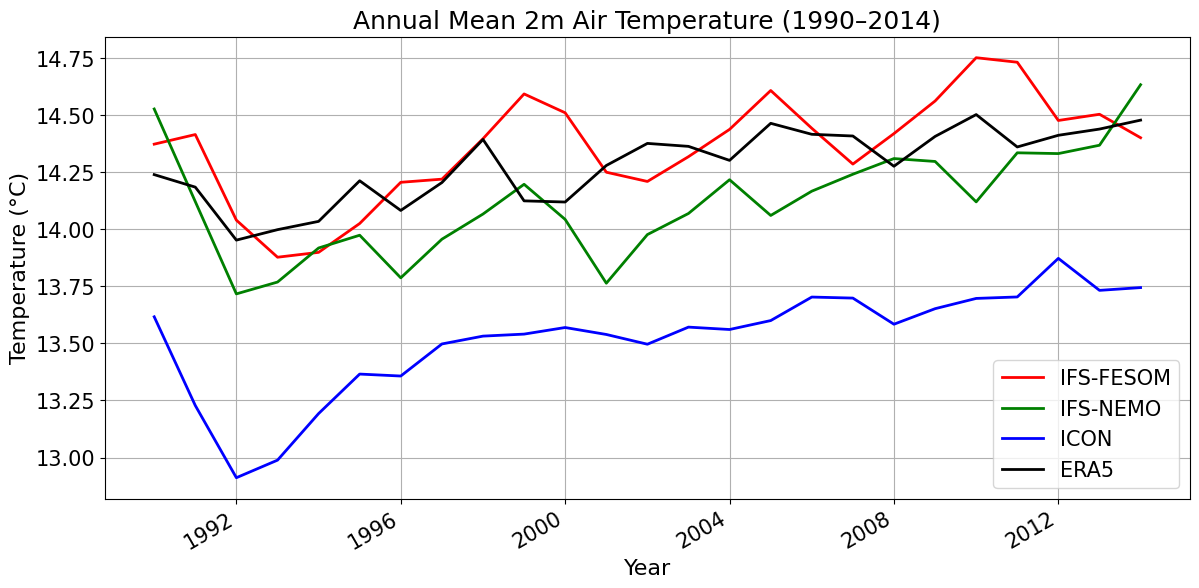

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14,6))

# Plot annual means
annual_mean_fesom.plot(label="IFS-FESOM", color='r', linewidth=2)
annual_mean_nemo.plot(label="IFS-NEMO", color='g', linewidth=2)
annual_mean_icon.plot(label="ICON", color='b', linewidth=2)
annual_mean_era.plot(label="ERA5", color="k" , linewidth=2)

plt.title("Annual Mean 2m Air Temperature (1990–2014)", fontsize=18)
plt.xlabel("Year", fontsize=16)
plt.ylabel("Temperature (°C)", fontsize=16)
plt.xticks(fontsize=15)
plt.yticks(fontsize=15)
plt.grid(True)
plt.legend(fontsize=15)
plt.show()

## Plot trends

In [15]:
annual_mean_fesom  # xarray.DataArray, time=25 (1990-2014)
annual_mean_nemo
annual_mean_icon
annual_mean_era

<xarray.DataArray 'var167' (time: 25)>
array([14.23906025, 14.18429489, 13.95222814, 13.99803076, 14.03434688,
       14.21212259, 14.08214525, 14.2043808 , 14.39300647, 14.12413331,
       14.11907215, 14.27908717, 14.37575325, 14.36279783, 14.30145334,
       14.46369655, 14.4155833 , 14.40816866, 14.27568854, 14.40634984,
       14.50198896, 14.36015395, 14.41127294, 14.43849671, 14.47765045])
Coordinates:
  * time     (time) datetime64[ns] 1990-01-01 1991-01-01 ... 2014-01-01

In [16]:
#Convert Dask arrays to NumPy

#Reasoning: xarray DataArrays may be backed by Dask, which is lazy. np.polyfit does not work correctly 
#on Dask arrays, it can return nonsense numbers.
# Convert to NumPy arrays
y_fesom = annual_mean_fesom.compute().values
y_nemo  = annual_mean_nemo.compute().values
y_icon  = annual_mean_icon.compute().values
y_era   = annual_mean_era.compute().values

# Numeric years
years = annual_mean_fesom.time.dt.year.values

In [17]:
print(years)
print(y_fesom[:5])

[1990 1991 1992 1993 1994 1995 1996 1997 1998 1999 2000 2001 2002 2003
 2004 2005 2006 2007 2008 2009 2010 2011 2012 2013 2014]
[14.37247995 14.41455297 14.03970955 13.87736618 13.89870449]


In [18]:
# Compute linear trends

# Reasoning:
# 	•	Linear trend: T = intercept + slope \times year
# 	•	Slope in °C/year, multiply by 10 → °C/decade
# 	•	To plot trend line that starts exactly at the first annual mean, we will use first-year value + slope × (year - first_year)

# Compute linear trend using np.polyfit
# slope in °C/year, intercept in °C
slope_fesom, intercept_fesom = np.polyfit(years, y_fesom, 1)
slope_nemo, intercept_nemo   = np.polyfit(years, y_nemo, 1)
slope_icon, intercept_icon   = np.polyfit(years, y_icon, 1)
slope_era, intercept_era     = np.polyfit(years, y_era, 1)

# Convert slope to °C/decade
trend_fesom_dec = slope_fesom * 10
trend_nemo_dec  = slope_nemo  * 10
trend_icon_dec  = slope_icon  * 10
trend_era_dec   = slope_era   * 10

print("Trends (°C/decade):", trend_fesom_dec, trend_nemo_dec, trend_icon_dec, trend_era_dec)


Trends (°C/decade): 0.1976683191495764 0.1869540169086461 0.2492093060605316 0.1719019669177032


In [19]:
# Compute trend lines aligned with first-year value

# Reasoning: Instead of using intercept (which may be slightly off due to fitting), we anchor the trend line at the first year’s value, and then extend using slope:

# First-year values
y0_fesom = y_fesom[0]
y0_nemo  = y_nemo[0]
y0_icon  = y_icon[0]
y0_era   = y_era[0]

# Trend per year for plotting
slope_fesom_year = trend_fesom_dec / 10
slope_nemo_year  = trend_nemo_dec  / 10
slope_icon_year  = trend_icon_dec  / 10
slope_era_year   = trend_era_dec   / 10

# Trend lines
trend_line_fesom = y0_fesom + slope_fesom_year * (years - years[0])
trend_line_nemo  = y0_nemo  + slope_nemo_year  * (years - years[0])
trend_line_icon  = y0_icon  + slope_icon_year  * (years - years[0])
trend_line_era   = y0_era   + slope_era_year   * (years - years[0])

# Quick check
print("FESOM trend line:", trend_line_fesom[0], "->", trend_line_fesom[-1])
print("ERA5 trend line:", trend_line_era[0], "->", trend_line_era[-1])

FESOM trend line: 14.372479946741302 -> 14.846883912700285
ERA5 trend line: 14.239060251187409 -> 14.651624971789897


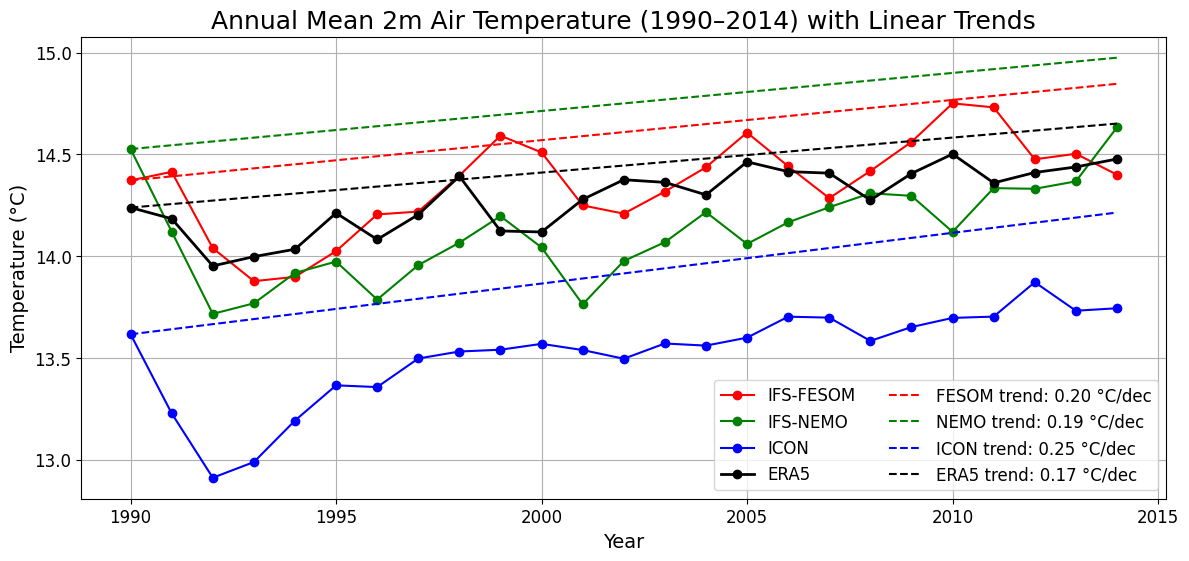

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14,6))

# Plot annual mean
plt.plot(years, y_fesom, marker='o', label='IFS-FESOM', color='r')
plt.plot(years, y_nemo, marker='o', label='IFS-NEMO', color='g')
plt.plot(years, y_icon, marker='o', label='ICON', color='b')
plt.plot(years, y_era, marker='o', label='ERA5', color='k', linewidth=2)

# Plot trend lines
plt.plot(years, trend_line_fesom, 'r--', label=f'FESOM trend: {trend_fesom_dec:.2f} °C/dec')
plt.plot(years, trend_line_nemo,  'g--', label=f'NEMO trend: {trend_nemo_dec:.2f} °C/dec')
plt.plot(years, trend_line_icon,  'b--', label=f'ICON trend: {trend_icon_dec:.2f} °C/dec')
plt.plot(years, trend_line_era,   'k--', label=f'ERA5 trend: {trend_era_dec:.2f} °C/dec')

# Labels and title
plt.title('Annual Mean 2m Air Temperature (1990–2014) with Linear Trends', fontsize=18)
plt.xlabel('Year', fontsize=14)
plt.ylabel('Temperature (°C)', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.grid(True)

# Legend: 2 columns, lower right
plt.legend(fontsize=12, loc='lower right', ncol=2, frameon=True)

plt.show()

In [21]:
# 1️⃣ Slice years from 1994 onwards
mask = years >= 1996
years_sub = years[mask]

y_fesom_sub = y_fesom[mask]
y_nemo_sub  = y_nemo[mask]
y_icon_sub  = y_icon[mask]
y_era_sub   = y_era[mask]

# 2️⃣ Compute linear trends on subset
slope_fesom_sub, intercept_fesom_sub = np.polyfit(years_sub, y_fesom_sub, 1)
slope_nemo_sub,  intercept_nemo_sub  = np.polyfit(years_sub, y_nemo_sub, 1)
slope_icon_sub,  intercept_icon_sub  = np.polyfit(years_sub, y_icon_sub, 1)
slope_era_sub,   intercept_era_sub   = np.polyfit(years_sub, y_era_sub, 1)

# Trend per decade
trend_fesom_sub_dec = slope_fesom_sub * 10
trend_nemo_sub_dec  = slope_nemo_sub * 10
trend_icon_sub_dec  = slope_icon_sub * 10
trend_era_sub_dec   = slope_era_sub * 10

print("Trends (°C/decade) from 1996:", 
      trend_fesom_sub_dec, trend_nemo_sub_dec, trend_icon_sub_dec, trend_era_sub_dec)

# 3️⃣ Compute trend lines anchored at first value of 1994
y0_fesom_sub = y_fesom_sub[0]
y0_nemo_sub  = y_nemo_sub[0]
y0_icon_sub  = y_icon_sub[0]
y0_era_sub   = y_era_sub[0]

# Trend per year
slope_fesom_sub_year = trend_fesom_sub_dec / 10
slope_nemo_sub_year  = trend_nemo_sub_dec  / 10
slope_icon_sub_year  = trend_icon_sub_dec  / 10
slope_era_sub_year   = trend_era_sub_dec   / 10

# Trend lines from 1994
trend_line_fesom_sub = y0_fesom_sub + slope_fesom_sub_year * (years_sub - years_sub[0])
trend_line_nemo_sub  = y0_nemo_sub  + slope_nemo_sub_year  * (years_sub - years_sub[0])
trend_line_icon_sub  = y0_icon_sub  + slope_icon_sub_year  * (years_sub - years_sub[0])
trend_line_era_sub   = y0_era_sub   + slope_era_sub_year   * (years_sub - years_sub[0])

Trends (°C/decade) from 1996: 0.1481515078232825 0.3050899346761553 0.18368488445229772 0.16324167447298785


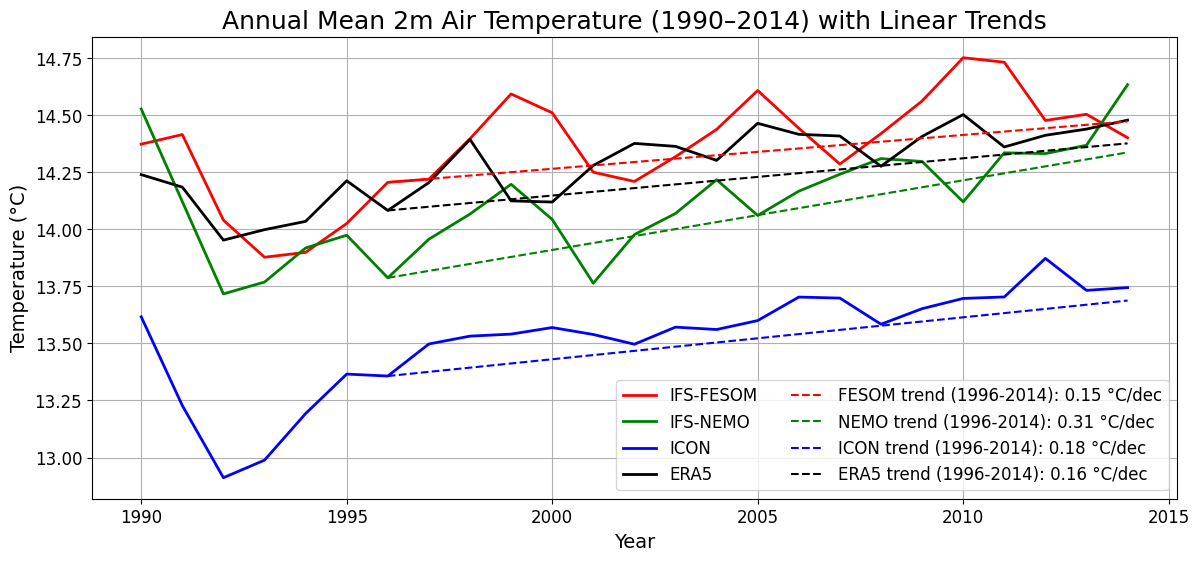

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14,6))

# Plot annual mean
# Plot annual mean (no markers)
plt.plot(years, y_fesom, label='IFS-FESOM', color='r', linewidth=2)
plt.plot(years, y_nemo,  label='IFS-NEMO',  color='g', linewidth=2)
plt.plot(years, y_icon,  label='ICON',      color='b', linewidth=2)
plt.plot(years, y_era,   label='ERA5',      color='k', linewidth=2)

# Plot trend lines
plt.plot(years_sub, trend_line_fesom_sub, 'r--', label=f'FESOM trend (1996-2014): {trend_fesom_sub_dec:.2f} °C/dec')
plt.plot(years_sub, trend_line_nemo_sub,  'g--', label=f'NEMO trend (1996-2014): {trend_nemo_sub_dec:.2f} °C/dec')
plt.plot(years_sub, trend_line_icon_sub,  'b--', label=f'ICON trend (1996-2014): {trend_icon_sub_dec:.2f} °C/dec')
plt.plot(years_sub, trend_line_era_sub,   'k--', label=f'ERA5 trend (1996-2014): {trend_era_sub_dec:.2f} °C/dec')

# Labels and title
plt.title('Annual Mean 2m Air Temperature (1990–2014) with Linear Trends', fontsize=18)
plt.xlabel('Year', fontsize=14)
plt.ylabel('Temperature (°C)', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.grid(True)

# Legend: 2 columns, lower right
plt.legend(fontsize=12, loc='lower right', ncol=2, frameon=True)

plt.show()

# Trend analysis: spatial plot

## Data preparation

In [24]:
# Models (already 1990–2014, but we enforce explicitly)

# Explicit time slice for safety
ds_fesom = ds_fesom.sel(time=slice("1990-01-01", "2014-12-31"))
ds_nemo  = ds_nemo.sel(time=slice("1990-01-01", "2014-12-31"))
ds_icon  = ds_icon.sel(time=slice("1990-01-01", "2014-12-31"))

# Extract temperature (convert to °C if still in K)
t2_fesom = ds_fesom['2t'] - 273.15
t2_nemo  = ds_nemo['2t']  - 273.15
t2_icon  = ds_icon['2t']  - 273.15

In [25]:
t2_fesom.shape, t2_nemo.shape, t2_icon.shape

((300, 180, 360), (300, 180, 360), (300, 180, 360))

In [30]:
# Save model data
t2_fesom.to_netcdf(f"{EVA_DIR}/IFS-FESOM_t2m_1990_2014_degC.nc")
t2_nemo.to_netcdf(f"{EVA_DIR}/IFS-NEMO_t2m_1990_2014_degC.nc")
t2_icon.to_netcdf(f"{EVA_DIR}/ICON_t2m_1990_2014_degC.nc")

In [27]:
# ERA5 (slice + already in °C)
t2_era = data_era_2t.sel(time=slice("1990-01-01", "2014-12-31"))
t2_era.shape

(300, 721, 1440)

In [29]:
# Save ERA data
t2_era.attrs['units'] = 'degC'
t2_era.to_netcdf(f"{EVA_DIR}/ERA5_t2m_1990_2014_degC.nc")

In [31]:
# Reload all datasets
t2_fesom = xr.open_dataarray(f"{EVA_DIR}/IFS-FESOM_t2m_1990_2014_degC.nc")
t2_nemo  = xr.open_dataarray(f"{EVA_DIR}/IFS-NEMO_t2m_1990_2014_degC.nc")
t2_icon  = xr.open_dataarray(f"{EVA_DIR}/ICON_t2m_1990_2014_degC.nc")
t2_era   = xr.open_dataarray(f"{EVA_DIR}/ERA5_t2m_1990_2014_degC.nc")

### Compute spatial linear trends (1990–2014)

In [32]:
# What we are doing (conceptually)

# For each grid cell (lat, lon):
# 	•	Take the monthly time series (1990–2014 → 300 points)
# 	•	Fit a linear regression
# 	•	Extract the slope
# 	•	Convert it to °C per decade
# This gives a 2D map of trends.

In [33]:
# Create numeric time axis (years)
import numpy as np

# Convert time to numeric years
time_years = (
    t2_fesom['time'].dt.year +
    (t2_fesom['time'].dt.month - 1) / 12
)
time_years.min().values, time_years.max().values

(array(1990.), array(2014.91666667))

In [34]:
# Define a reusable trend function
# We need a function that:
# 	•	works on 1D time series
# 	•	ignores NaNs
# 	•	returns slope only

def linear_trend(x, y):
    """Return slope of linear fit y = a*x + b"""
    mask = np.isfinite(y)
    if mask.sum() < 2:
        return np.nan
    return np.polyfit(x[mask], y[mask], 1)[0]

In [35]:
#  Compute spatial trend (xarray-native)

trend_fesom = xr.apply_ufunc(
    linear_trend,
    time_years,
    t2_fesom,
    input_core_dims=[['time'], ['time']],
    vectorize=True,
    dask='parallelized',
    output_dtypes=[float]
)

In [36]:
# Convert to °C/decade:
trend_fesom_dec = trend_fesom * 10
trend_fesom_dec.attrs['units'] = 'degC/decade'
trend_fesom_dec.name = 't2m_trend'

trend_fesom_dec.shape

(180, 360)

In [38]:
# Repeat for all datasets

trend_nemo_dec = xr.apply_ufunc(
    linear_trend, time_years, t2_nemo,
    input_core_dims=[['time'], ['time']],
    vectorize=True, dask='parallelized',
    output_dtypes=[float]
) * 10

trend_icon_dec = xr.apply_ufunc(
    linear_trend, time_years, t2_icon,
    input_core_dims=[['time'], ['time']],
    vectorize=True, dask='parallelized',
    output_dtypes=[float]
) * 10


In [48]:
# Add meta data and save

for da in [trend_nemo_dec, trend_icon_dec]:
    da.attrs['units'] = 'degC/decade'
    da.name = 't2m_trend'

trend_fesom_dec.to_netcdf(f"{EVA_DIR}/IFS-FESOM_t2m_trend_1990_2014.nc")
trend_nemo_dec.to_netcdf(f"{EVA_DIR}/IFS-NEMO_t2m_trend_1990_2014.nc")
trend_icon_dec.to_netcdf(f"{EVA_DIR}/ICON_t2m_trend_1990_2014.nc")


In [43]:
# For ERA
# Convert time to decimal years (relative, not absolute)
time_years_era = (
    t2_era['time'].dt.year
    + (t2_era['time'].dt.month - 0.5) / 12.0
)

# Make it relative (improves numerical stability)
time_years_era = time_years_era - time_years_era[0]

time_years_era.shape

(300,)

In [44]:
trend_era = xr.apply_ufunc(
    linear_trend,
    time_years_era,
    t2_era,
    input_core_dims=[['time'], ['time']],
    output_core_dims=[[]],
    vectorize=True,
    dask='parallelized',
    output_dtypes=[float],
)

In [45]:
# Convert to °C / decade
trend_era_dec = trend_era * 10.0
trend_era_dec.name = "t2m_trend"
trend_era_dec.attrs['units'] = 'degC/decade'

trend_era_dec.shape
# (721, 1440)

(721, 1440)

In [46]:
# Save ERA trend to NetCDF
trend_era_dec.to_netcdf(
    f"{EVA_DIR}/ERA5_t2m_trend_1990_2014_degC_decade.nc"
)

### Plot spatial data: comparison

In [1]:
# 
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

In [2]:
# Load all pre-computed trend fields

trend_fesom = xr.open_dataarray(
    f"{EVA_DIR}/IFS-FESOM_t2m_trend_1990_2014.nc"
)

trend_nemo = xr.open_dataarray(
    f"{EVA_DIR}/IFS-NEMO_t2m_trend_1990_2014.nc"
)

trend_icon = xr.open_dataarray(
    f"{EVA_DIR}/ICON_t2m_trend_1990_2014.nc"
)

trend_era = xr.open_dataarray(
    f"{EVA_DIR}/ERA5_t2m_trend_1990_2014_degC_decade.nc"
)

In [3]:
vmin = -1.0
vmax = 1
levels = np.linspace(vmin, vmax, 21)

In [4]:
def plot_trend_map(ax, da, title):
    im = da.plot(
        ax=ax,
        transform=ccrs.PlateCarree(),
        cmap='RdBu_r',
        vmin=vmin,
        vmax=vmax,
        add_colorbar=False
    )
    ax.coastlines(linewidth=0.8)
    ax.add_feature(cfeature.BORDERS, linewidth=0.3)
    ax.set_title(title, fontsize=11)
    return im

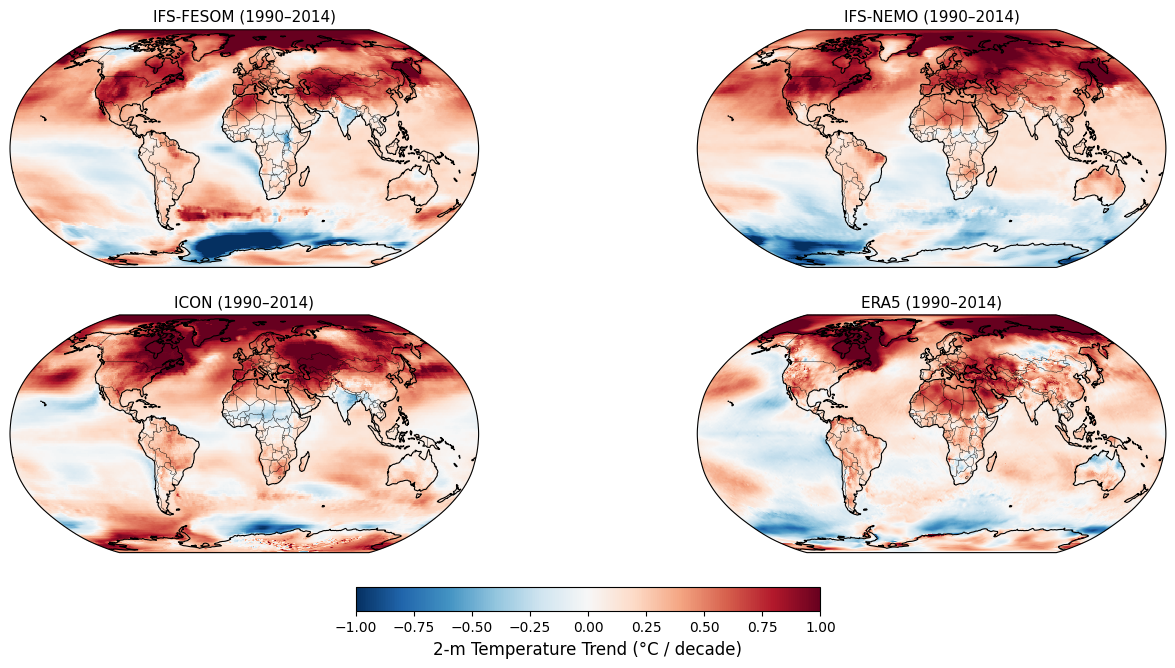

In [5]:
fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 7),
    subplot_kw={'projection': ccrs.Robinson()}
)

im = plot_trend_map(axes[0, 0], trend_fesom, "IFS-FESOM (1990–2014)")
plot_trend_map(axes[0, 1], trend_nemo,  "IFS-NEMO (1990–2014)")
plot_trend_map(axes[1, 0], trend_icon,  "ICON (1990–2014)")
plot_trend_map(axes[1, 1], trend_era,   "ERA5 (1990–2014)")

# ---- MANUAL SPACE FOR COLORBAR ----
fig.subplots_adjust(bottom=0.12, top=0.95, left=0.05, right=0.95)

cbar = fig.colorbar(
    im,
    ax=axes.ravel().tolist(),
    orientation='horizontal',
    pad=0.06,
    fraction=0.04
)
cbar.set_label("2-m Temperature Trend (°C / decade)", fontsize=12)

plt.show()

## Plot 'ERA - model' trends

In [6]:
# check
print("FESOM")
print(trend_fesom)
print("\nNEMO")
print(trend_nemo)
print("\nICON")
print(trend_icon)
print("\nERA5")
print(trend_era)

FESOM
<xarray.DataArray 't2m_trend' (lat: 180, lon: 360)>
[64800 values with dtype=float64]
Coordinates:
  * lat      (lat) float64 -89.5 -88.5 -87.5 -86.5 -85.5 ... 86.5 87.5 88.5 89.5
  * lon      (lon) float64 0.0 1.0 2.0 3.0 4.0 ... 355.0 356.0 357.0 358.0 359.0
Attributes:
    units:    degC/decade

NEMO
<xarray.DataArray 't2m_trend' (lat: 180, lon: 360)>
[64800 values with dtype=float64]
Coordinates:
  * lat      (lat) float64 -89.5 -88.5 -87.5 -86.5 -85.5 ... 86.5 87.5 88.5 89.5
  * lon      (lon) float64 0.0 1.0 2.0 3.0 4.0 ... 355.0 356.0 357.0 358.0 359.0
Attributes:
    units:    degC/decade

ICON
<xarray.DataArray 't2m_trend' (lat: 180, lon: 360)>
[64800 values with dtype=float64]
Coordinates:
  * lat      (lat) float64 -89.5 -88.5 -87.5 -86.5 -85.5 ... 86.5 87.5 88.5 89.5
  * lon      (lon) float64 0.0 1.0 2.0 3.0 4.0 ... 355.0 356.0 357.0 358.0 359.0
Attributes:
    units:    degC/decade

ERA5
<xarray.DataArray 't2m_trend' (lat: 721, lon: 1440)>
[1038240 values with dtype

In [7]:
# Use FESOM grid as reference (same as NEMO & ICON)
target_lat = trend_fesom.lat
target_lon = trend_fesom.lon

In [8]:
# Fix ERA5 longitude convention
# ERA5 is −180 → 180, models are 0 → 360.
# Convert ERA5 lon from [-180, 180] → [0, 360]
trend_era_360 = trend_era.assign_coords(
    lon=(trend_era.lon + 360) % 360
).sortby("lon")

In [9]:
# Regrid ERA5 to 1° × 1° (bilinear)

trend_era_regrid = trend_era_360.interp(
    lat=target_lat,
    lon=target_lon,
    method="linear"
)

In [10]:
# Sanity checks (DO NOT SKIP)

print(trend_era_regrid)
print("\nLat identical:", trend_era_regrid.lat.equals(trend_fesom.lat))
print("Lon identical:", trend_era_regrid.lon.equals(trend_fesom.lon))
print("Units:", trend_era_regrid.attrs.get("units"))

<xarray.DataArray 't2m_trend' (lat: 180, lon: 360)>
array([[-0.07974659, -0.07937534, -0.07895122, ..., -0.08098994,
        -0.0805903 , -0.08018748],
       [-0.03963146, -0.03812108, -0.03650799, ..., -0.04371104,
        -0.04232753, -0.04091371],
       [ 0.02669818,  0.03020671,  0.03376608, ...,  0.01482034,
         0.01872674,  0.02270751],
       ...,
       [ 0.53490773,  0.53737033,  0.53968751, ...,  0.5252407 ,
         0.52853694,  0.53171468],
       [ 0.62374358,  0.62621048,  0.62861374, ...,  0.61545135,
         0.61821581,  0.62092219],
       [ 0.742178  ,  0.74365203,  0.74497678, ...,  0.739675  ,
         0.74056309,  0.74135627]])
Coordinates:
  * lat      (lat) float64 -89.5 -88.5 -87.5 -86.5 -85.5 ... 86.5 87.5 88.5 89.5
  * lon      (lon) float64 0.0 1.0 2.0 3.0 4.0 ... 355.0 356.0 357.0 358.0 359.0
Attributes:
    units:    degC/decade

Lat identical: True
Lon identical: True
Units: degC/decade


In [11]:
# Save regridded ERA5

trend_era_regrid.name = "t2m_trend"
trend_era_regrid.attrs["description"] = "ERA5 2m temperature trend regridded to 1x1 model grid (1990–2014)"

trend_era_regrid.to_netcdf(
    f"{EVA_DIR}/ERA5_t2m_trend_1990_2014_regrid1deg.nc"
)

### Plot

In [12]:
# ERA5 minus models
diff_era_fesom = trend_era_regrid - trend_fesom
diff_era_nemo  = trend_era_regrid - trend_nemo
diff_era_icon  = trend_era_regrid - trend_icon

In [13]:
# Add Metadata and Save

for da, name in zip(
    [diff_era_fesom, diff_era_nemo, diff_era_icon],
    ["ERA5_minus_IFS-FESOM", "ERA5_minus_IFS-NEMO", "ERA5_minus_ICON"]
):
    da.name = "t2m_trend_difference"
    da.attrs["units"] = "degC/decade"
    da.attrs["description"] = f"{name} (1990–2014)"

# Save
diff_era_fesom.to_netcdf(
    f"{EVA_DIR}/ERA5_minus_IFS-FESOM_t2m_trend_1990_2014.nc"
)

diff_era_nemo.to_netcdf(
    f"{EVA_DIR}/ERA5_minus_IFS-NEMO_t2m_trend_1990_2014.nc"
)

diff_era_icon.to_netcdf(
    f"{EVA_DIR}/ERA5_minus_ICON_t2m_trend_1990_2014.nc"
)

In [14]:
## Check data

print("ERA-FESOM min/max:", float(diff_era_fesom.min()), float(diff_era_fesom.max()))
print("ERA-NEMO  min/max:", float(diff_era_nemo.min()),  float(diff_era_nemo.max()))
print("ERA-ICON  min/max:", float(diff_era_icon.min()),  float(diff_era_icon.max()))

ERA-FESOM min/max: -2.3764444446380635 2.7267570371631256
ERA-NEMO  min/max: -1.8168803613328814 1.9758370567436372
ERA-ICON  min/max: -3.221156743785175 1.9326809840161305


In [15]:
import numpy as np

vmax = np.max([
    np.abs(diff_era_fesom).max(),
    np.abs(diff_era_nemo).max(),
    np.abs(diff_era_icon).max()
]).item()

vmax = np.round(vmax, 1)  # cleaner colorbar
vmin = -vmax

vmin, vmax

(-3.2, 3.2)

/tmp/ipykernel_1563677/3412957007.py:46: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


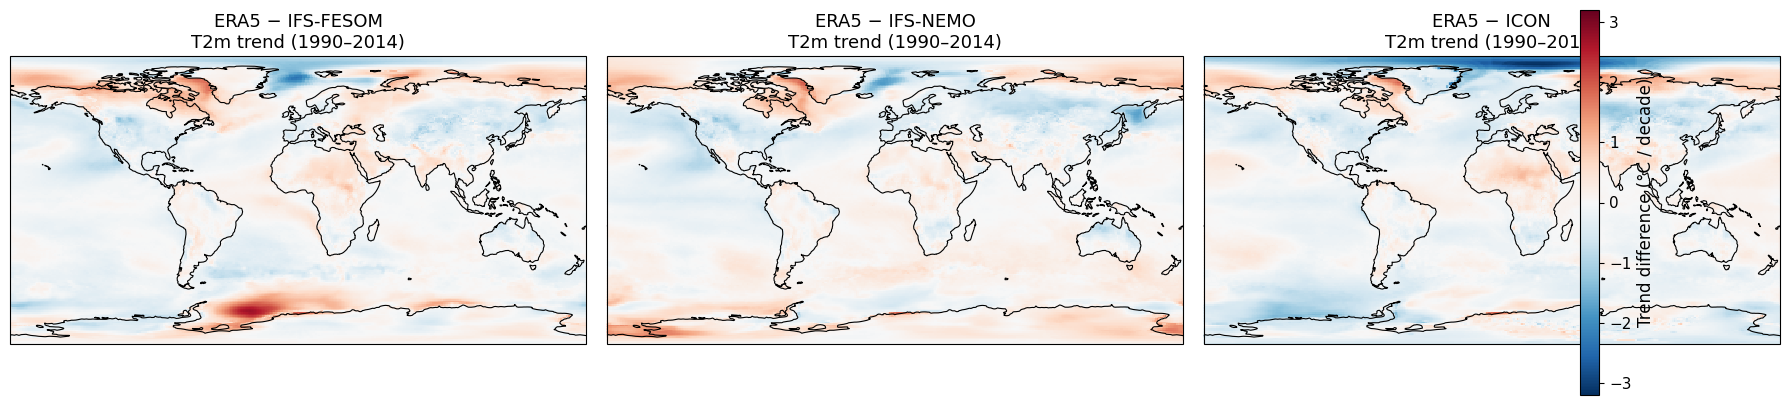

In [16]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

fig, axes = plt.subplots(
    nrows=1, ncols=3,
    figsize=(18, 5),
    subplot_kw={"projection": ccrs.PlateCarree()}
)

datasets = [
    diff_era_fesom,
    diff_era_nemo,
    diff_era_icon
]

titles = [
    "ERA5 − IFS-FESOM\nT2m trend (1990–2014)",
    "ERA5 − IFS-NEMO\nT2m trend (1990–2014)",
    "ERA5 − ICON\nT2m trend (1990–2014)"
]

for ax, da, title in zip(axes, datasets, titles):
    im = da.plot(
        ax=ax,
        transform=ccrs.PlateCarree(),
        cmap="RdBu_r",
        vmin=vmin,
        vmax=vmax,
        add_colorbar=False
    )
    ax.coastlines(linewidth=0.8)
    ax.set_title(title, fontsize=13)
    ax.set_global()

# Shared colorbar (right side, non-overlapping)
cbar = fig.colorbar(
    im,
    ax=axes,
    orientation="vertical",
    fraction=0.025,
    pad=0.04
)
cbar.set_label("Trend difference (°C / decade)", fontsize=12)
cbar.ax.tick_params(labelsize=11)

plt.tight_layout()
plt.show()

/sw/spack-levante/mambaforge-22.9.0-2-Linux-x86_64-kptncg/lib/python3.10/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/sw/spack-levante/mambaforge-22.9.0-2-Linux-x86_64-kptncg/lib/python3.10/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 128309 (\N{LARGE BLUE CIRCLE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/sw/spack-levante/mambaforge-22.9.0-2-Linux-x86_64-kptncg/lib/python3.10/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/sw/spack-levante/mambaforge-22.9.0-2-Linux-x86_64-kptncg/lib/python3.10/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 128309 (\N{LARGE BLUE CIRCLE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


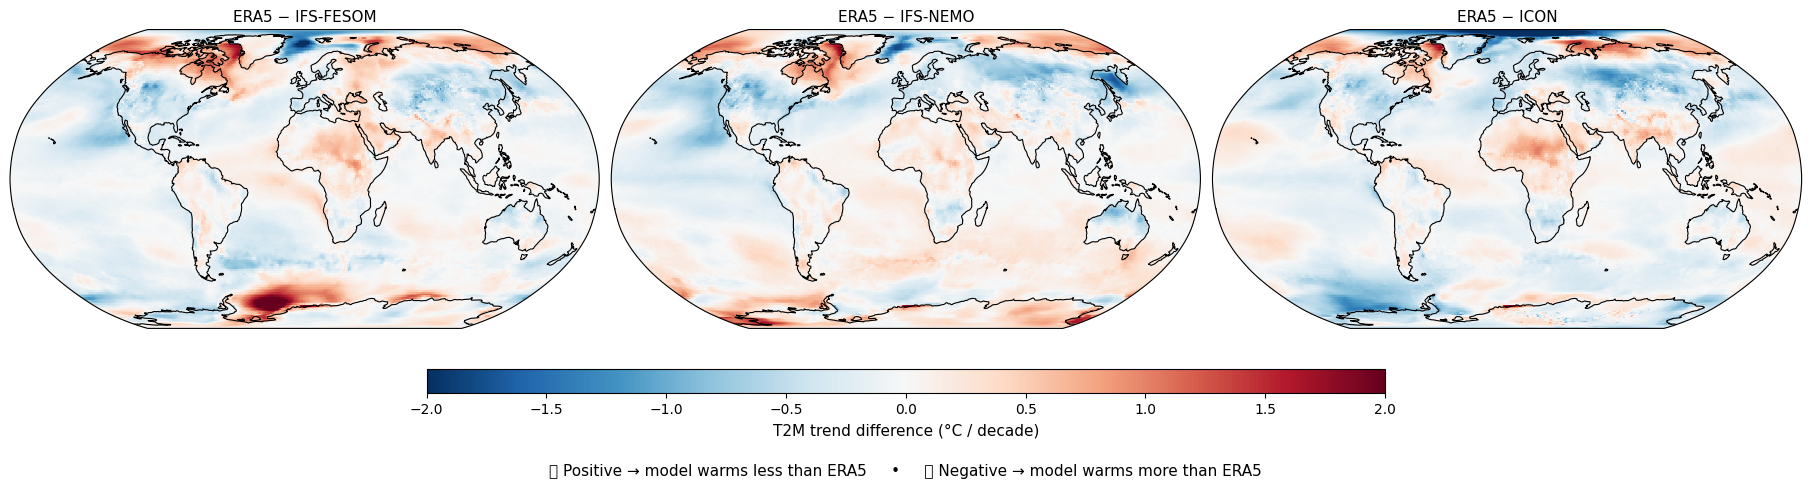

In [17]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

# Use your existing DataArrays
diffs = [
    diff_era_fesom,
    diff_era_nemo,
    diff_era_icon
]

titles = [
    "ERA5 − IFS-FESOM",
    "ERA5 − IFS-NEMO",
    "ERA5 − ICON"
]

proj = ccrs.Robinson()

fig, axes = plt.subplots(
    nrows=1,
    ncols=3,
    figsize=(18, 6),
    subplot_kw=dict(projection=proj),
    constrained_layout=True
)

# Symmetric color limits
# vmax = max(abs(da.max().item()) for da in diffs)
# vmin = -vmax

vmax = 2
vmin = -2

for ax, da, title in zip(axes, diffs, titles):
    im = da.plot(
        ax=ax,
        transform=ccrs.PlateCarree(),
        cmap="RdBu_r",
        vmin=vmin,
        vmax=vmax,
        add_colorbar=False
    )
    ax.coastlines(linewidth=0.8)
    ax.set_title(title, fontsize=11)

# ---- Shared colorbar (bottom, no overlap) ----
cbar = fig.colorbar(
    im,
    ax=axes,
    orientation="horizontal",
    fraction=0.05,
    pad=0.08,
    aspect=40
)
cbar.set_label("T2M trend difference (°C / decade)", fontsize=11)

# ---- Interpretation text ----
fig.text(
    0.5, -0.05,
    "🔴 Positive → model warms less than ERA5     •     🔵 Negative → model warms more than ERA5",
    ha="center",
    fontsize=11
)

plt.show()

### Zonal mean trends

/tmp/ipykernel_1988496/318651220.py:43: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1988496/318651220.py:43: UserWarning: Glyph 128309 (\N{LARGE BLUE CIRCLE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


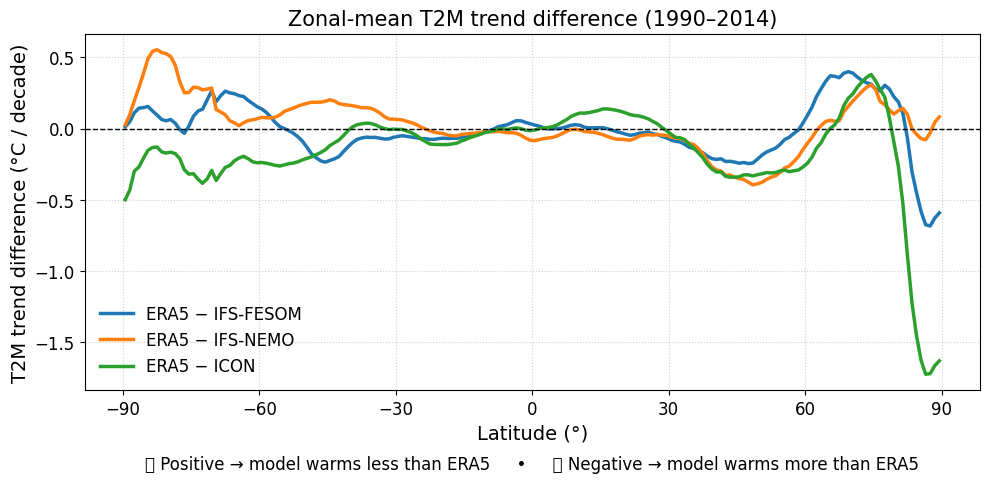

In [28]:
import matplotlib.pyplot as plt

# Zonal means already computed
# zm_fesom, zm_nemo, zm_icon

plt.figure(figsize=(10, 5))

plt.plot(zm_fesom.lat, zm_fesom, label="ERA5 − IFS-FESOM", linewidth=2.5)
plt.plot(zm_nemo.lat,  zm_nemo,  label="ERA5 − IFS-NEMO",  linewidth=2.5)
plt.plot(zm_icon.lat,  zm_icon,  label="ERA5 − ICON",     linewidth=2.5)

# Zero reference line
plt.axhline(0, color="k", linestyle="--", linewidth=1)

# Axes labels (bigger)
plt.xlabel("Latitude (°)", fontsize=14)
plt.ylabel("T2M trend difference (°C / decade)", fontsize=14)

# Latitude ticks exactly as requested
plt.xticks(
    [-90, -60, -30, 0, 30, 60, 90],
    fontsize=12
)
plt.yticks(fontsize=12)

plt.title(
    "Zonal-mean T2M trend difference (1990–2014)",
    fontsize=15
)

plt.legend(fontsize=12, frameon=False)
plt.grid(True, linestyle=":", alpha=0.6)

# Interpretation note
plt.text(
    0.5, -0.22,
    "🔴 Positive → model warms less than ERA5     •     🔵 Negative → model warms more than ERA5",
    ha="center",
    transform=plt.gca().transAxes,
    fontsize=12
)

plt.tight_layout()
plt.show()

In [24]:
print(zm_fesom.min().item(), zm_fesom.max().item())
print(zm_nemo.min().item(),  zm_nemo.max().item())
print(zm_icon.min().item(),  zm_icon.max().item())

-0.683106432591422 0.3991330277649041
-0.3948003592478099 0.5531156604035863
-1.7231204977397314 0.3793863693470235


# Spatial standard deviation: 2m-temp

In [ ]:
# How variable 2 m temperature is at each grid point, after removing the long-term warming tren
# This isolates climate variability, not climate change.

# 1️⃣ “First detrend the time series”
# At each grid point (lat, lon):
# 	•	You have a time series: T(t)
# 	•	You remove the linear trend (warming signal)
# 	•	What remains = interannual / internal variability

# Mathematically:
# T'(t) = T(t) - (a t + b)

# So:
# 	•	Trend → forced signal
# 	•	Residuals → variability

# 2️⃣ “Spatial standard deviation of 2m temperature”

# After detrending:
# 	•	Compute standard deviation over time at each grid point:
# \sigma(x,y) = \text{std}\big(T'(t,x,y)\big)

# Result:
# 	•	A map of temperature variability (°C)
# 	•	High σ → large year-to-year swings
# 	•	Low σ → stable climate

In [2]:
# Step 1: Load the temperature files (1990–2014, in °C) and regrid ERA5 to model grid
import xarray as xr
import numpy as np

# File paths
file_fesom = f"{EVA_DIR}/IFS-FESOM_t2m_1990_2014_degC.nc"
file_nemo  = f"{EVA_DIR}/IFS-NEMO_t2m_1990_2014_degC.nc"
file_icon  = f"{EVA_DIR}/ICON_t2m_1990_2014_degC.nc"
file_era   = f"{EVA_DIR}/ERA5_t2m_1990_2014_degC.nc"

# Load DataArrays
t2_ifs_fesom = xr.open_dataarray(file_fesom)
t2_ifs_nemo  = xr.open_dataarray(file_nemo)
t2_icon      = xr.open_dataarray(file_icon)
t2_era       = xr.open_dataarray(file_era)

# Check shapes and coordinates
print("IFS-FESOM:", t2_ifs_fesom.shape, t2_ifs_fesom.dims)
print("IFS-NEMO :", t2_ifs_nemo.shape, t2_ifs_nemo.dims)
print("ICON     :", t2_icon.shape, t2_icon.dims)
print("ERA5     :", t2_era.shape, t2_era.dims)

IFS-FESOM: (300, 180, 360) ('time', 'lat', 'lon')
IFS-NEMO : (300, 180, 360) ('time', 'lat', 'lon')
ICON     : (300, 180, 360) ('time', 'lat', 'lon')
ERA5     : (300, 721, 1440) ('time', 'lat', 'lon')


In [11]:
# Step 2: Check time coordinate consistency and type

print("Time dtype (IFS-FESOM):", t2_ifs_fesom.time.dtype)
print("Time dtype (ERA5):", t2_era.time.dtype)

print("First / last time (IFS-FESOM):", 
      t2_ifs_fesom.time.values[0], t2_ifs_fesom.time.values[-1])

print("First / last time (ERA5):", 
      t2_era.time.values[0], t2_era.time.values[-1])

print("Time length equal:",
      len(t2_ifs_fesom.time) == len(t2_era.time))

Time dtype (IFS-FESOM): datetime64[ns]
Time dtype (ERA5): datetime64[ns]
First / last time (IFS-FESOM): 1990-01-01T00:00:00.000000000 2014-12-01T00:00:00.000000000
First / last time (ERA5): 1990-01-01T12:00:00.000000000 2014-12-01T12:00:00.000000000
Time length equal: True


In [12]:
# Step 3: Verify that all model grids are identical

print("Model lat identical (FESOM vs NEMO):",
      np.array_equal(t2_ifs_fesom.lat, t2_ifs_nemo.lat))

print("Model lon identical (FESOM vs NEMO):",
      np.array_equal(t2_ifs_fesom.lon, t2_ifs_nemo.lon))

print("Model lat identical (FESOM vs ICON):",
      np.array_equal(t2_ifs_fesom.lat, t2_icon.lat))

print("Model lon identical (FESOM vs ICON):",
      np.array_equal(t2_ifs_fesom.lon, t2_icon.lon))

Model lat identical (FESOM vs NEMO): True
Model lon identical (FESOM vs NEMO): True
Model lat identical (FESOM vs ICON): True
Model lon identical (FESOM vs ICON): True


In [13]:
# Step 4: Inspect ERA5 latitude and longitude orientation

print("ERA5 lat min/max:", float(t2_era.lat.min()), float(t2_era.lat.max()))
print("ERA5 lon min/max:", float(t2_era.lon.min()), float(t2_era.lon.max()))

print("ERA5 lat increasing:",
      np.all(np.diff(t2_era.lat.values) > 0))

print("ERA5 lon increasing:",
      np.all(np.diff(t2_era.lon.values) > 0))

ERA5 lat min/max: -90.0 90.0
ERA5 lon min/max: -180.0 179.75
ERA5 lat increasing: True
ERA5 lon increasing: True


In [14]:
# Step 5: Check NaN statistics BEFORE detrending

def nan_report(da, name):
    n_total = da.size
    n_nan = int(np.isnan(da.values).sum())
    print(f"{name}: NaNs = {n_nan}, Fraction = {n_nan / n_total:.4f}")

nan_report(t2_ifs_fesom, "IFS-FESOM")
nan_report(t2_ifs_nemo,  "IFS-NEMO")
nan_report(t2_icon,      "ICON")
nan_report(t2_era,       "ERA5 (native)")

IFS-FESOM: NaNs = 0, Fraction = 0.0000
IFS-NEMO: NaNs = 0, Fraction = 0.0000
ICON: NaNs = 0, Fraction = 0.0000
ERA5 (native): NaNs = 0, Fraction = 0.0000


In [15]:
# Step 6: Check if NaN mask is time-invariant (critical for detrending)

def time_invariant_mask(da, name):
    mask_t0 = np.isnan(da.isel(time=0))
    mask_all = np.isnan(da).any(dim="time")
    identical = np.array_equal(mask_t0, mask_all)
    print(f"{name}: Time-invariant NaN mask =", identical)

time_invariant_mask(t2_ifs_fesom, "IFS-FESOM")
time_invariant_mask(t2_ifs_nemo,  "IFS-NEMO")
time_invariant_mask(t2_icon,      "ICON")
time_invariant_mask(t2_era,       "ERA5")

IFS-FESOM: Time-invariant NaN mask = True
IFS-NEMO: Time-invariant NaN mask = True
ICON: Time-invariant NaN mask = True
ERA5: Time-invariant NaN mask = True


In [16]:
# Step 8: Detrend temperature time series at each grid point
# This removes the long-term warming signal and isolates variability

def detrend_time(da):
    """
    Remove linear trend along the time dimension using xarray.polyfit.
    Returns detrended DataArray with same shape.
    """
    # Fit linear trend: T(t) = a*t + b
    coeffs = da.polyfit(dim="time", deg=1)

    # Reconstruct the trend
    trend = xr.polyval(da["time"], coeffs.polyfit_coefficients)

    # Subtract trend
    da_detrended = da - trend

    return da_detrended


# Apply detrending
t2_ifs_fesom_dt = detrend_time(t2_ifs_fesom)
t2_ifs_nemo_dt  = detrend_time(t2_ifs_nemo)
t2_icon_dt      = detrend_time(t2_icon)
t2_era_dt       = detrend_time(t2_era)

In [17]:
# Step 9: Check basic statistics after detrending

def detrend_report(da, name):
    print(f"{name}:")
    print("  mean (global):", float(da.mean()))
    print("  min / max    :", float(da.min()), float(da.max()))
    print("  NaNs         :", int(np.isnan(da.values).sum()))
    print()

detrend_report(t2_ifs_fesom_dt, "IFS-FESOM detrended")
detrend_report(t2_ifs_nemo_dt,  "IFS-NEMO detrended")
detrend_report(t2_icon_dt,      "ICON detrended")
detrend_report(t2_era_dt,       "ERA5 detrended")

IFS-FESOM detrended:
  mean (global): -1.9551329005705079e-16
  min / max    : -34.96661292910854 29.874135512832574
  NaNs         : 0

IFS-NEMO detrended:
  mean (global): -6.344006253107463e-17
  min / max    : -33.77061787845339 29.515681579187635
  NaNs         : 0

ICON detrended:
  mean (global): 8.767454069560018e-17
  min / max    : -36.269441997598165 34.79623851015489
  NaNs         : 0

ERA5 detrended:
  mean (global): -2.79057474376622e-16
  min / max    : -40.29739300973994 34.60811328226491
  NaNs         : 0



In [18]:
# Step 10: Compute temporal standard deviation of detrended temperature
# This quantifies local temperature variability (interannual / monthly)

t2_ifs_fesom_std = t2_ifs_fesom_dt.std(dim="time")
t2_ifs_nemo_std  = t2_ifs_nemo_dt.std(dim="time")
t2_icon_std      = t2_icon_dt.std(dim="time")
t2_era_std       = t2_era_dt.std(dim="time")

In [19]:
# Step 11: Check ranges and NaNs of variability fields

def std_report(da, name):
    print(f"{name}:")
    print("  shape        :", da.shape)
    print("  min / max    :", float(da.min()), float(da.max()))
    print("  mean         :", float(da.mean()))
    print("  NaNs         :", int(np.isnan(da.values).sum()))
    print()

std_report(t2_ifs_fesom_std, "IFS-FESOM std")
std_report(t2_ifs_nemo_std,  "IFS-NEMO std")
std_report(t2_icon_std,      "ICON std")
std_report(t2_era_std,       "ERA5 std")

IFS-FESOM std:
  shape        : (180, 360)
  min / max    : 0.28105394570578074 19.727634915653706
  mean         : 5.737103611304865
  NaNs         : 0

IFS-NEMO std:
  shape        : (180, 360)
  min / max    : 0.2918328585906012 19.70609696471767
  mean         : 5.293443154840837
  NaNs         : 0

ICON std:
  shape        : (180, 360)
  min / max    : 0.296828763698784 20.64428097692656
  mean         : 5.627025277932873
  NaNs         : 0

ERA5 std:
  shape        : (721, 1440)
  min / max    : 0.22639255465253327 23.294673272132123
  mean         : 5.185857243417747
  NaNs         : 0



In [20]:
# Step 12a: Convert ERA5 longitude from [-180, 180] to [0, 360]
# This avoids half-globe plotting issues and ensures consistency with models

t2_era_std_fixlon = t2_era_std.assign_coords(
    lon=(t2_era_std.lon % 360)
).sortby("lon")

# Sanity check
print("ERA5 lon min/max after fix:",
      float(t2_era_std_fixlon.lon.min()),
      float(t2_era_std_fixlon.lon.max()))

ERA5 lon min/max after fix: 0.0 359.75


In [21]:
# Step 12b: Regrid ERA5 std field to model grid
# We interpolate variability (std), NOT the original time series

t2_era_std_regrid = t2_era_std_fixlon.interp(
    lat=t2_ifs_fesom_std.lat,
    lon=t2_ifs_fesom_std.lon,
    method="linear"
)

# Final sanity check
print("ERA5 regridded std:")
print("  shape     :", t2_era_std_regrid.shape)
print("  min / max :", float(t2_era_std_regrid.min()),
                     float(t2_era_std_regrid.max()))
print("  NaNs      :", int(np.isnan(t2_era_std_regrid.values).sum()))

ERA5 regridded std:
  shape     : (180, 360)
  min / max : 0.22891449812088788 22.921805641133002
  NaNs      : 0


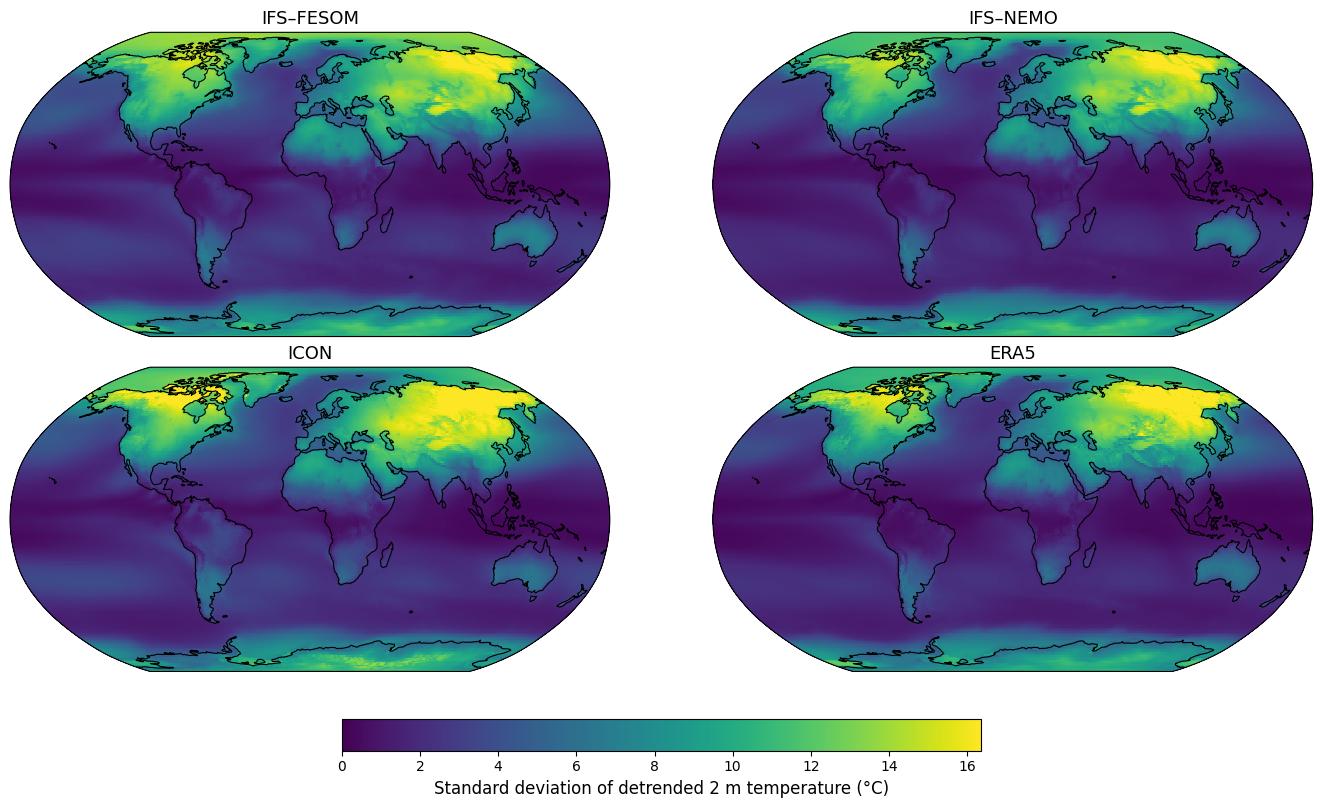

In [22]:
# Step 13: Plot spatial standard deviation of detrended 2m temperature
# Purpose:
#   • Compare temperature variability across datasets
#   • Same grid, same units, same color scale
#   • Clean layout with non-overlapping shared colorbar

import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import numpy as np

# Collect datasets and titles
data = [
    t2_ifs_fesom_std,
    t2_ifs_nemo_std,
    t2_icon_std,
    t2_era_std_regrid
]

titles = [
    "IFS–FESOM",
    "IFS–NEMO",
    "ICON",
    "ERA5"
]

# Color scale (robust, shared)
vmin = 0
vmax = np.percentile(
    np.concatenate([d.values.ravel() for d in data]),
    99
)

proj = ccrs.Robinson()

fig, axes = plt.subplots(
    nrows=2, ncols=2,
    figsize=(14, 8),
    subplot_kw={"projection": proj},
    constrained_layout=True
)

axes = axes.flatten()

for ax, da, title in zip(axes, data, titles):
    im = da.plot(
        ax=ax,
        transform=ccrs.PlateCarree(),
        cmap="viridis",
        vmin=vmin,
        vmax=vmax,
        add_colorbar=False
    )
    ax.coastlines(linewidth=0.8)
    ax.set_title(title, fontsize=13)

# Shared colorbar (bottom, no overlap)
cbar = fig.colorbar(
    im,
    ax=axes,
    orientation="horizontal",
    fraction=0.05,
    pad=0.07
)

cbar.set_label(
    "Standard deviation of detrended 2 m temperature (°C)",
    fontsize=12
)

plt.show()

* Detrended 2 m Temperature Variability (1990–2014)

**Objective:**  
We quantify the interannual variability of near-surface air temperature across multiple climate models (IFS-FESOM, IFS-NEMO, ICON) and the ERA5 reanalysis by computing the **spatial standard deviation** of **detrended monthly 2 m temperature**.

**Procedure:**  
1. **Data loading:** Monthly 2 m temperature for 1990–2014 from each model and ERA5 reanalysis.  
2. **Temporal alignment:** Verified that time coordinates match across datasets.  
3. **Detrending:** Removed linear trends along the time dimension to focus on variability rather than long-term warming.  
4. **Standard deviation computation:** Calculated standard deviation at each grid point over the detrended time series.  
5. **Regridding (ERA5):** ERA5 was regridded to the common 180 × 360 grid of the models for direct spatial comparison.  
6. **Visualization:** Plotted global maps of detrended temperature standard deviation using a shared color scale (0–16 °C) to facilitate comparison.

**Results / Notes:**  
- The standard deviation ranges approximately from **0 °C (stable tropical oceans)** to **~16 °C (high-latitude continental regions)**, which is physically consistent with expected interannual variability.  
- Models and reanalysis exhibit similar global patterns of variability, with maxima in continental interiors and polar regions, and minima over the tropics and oceans.  
- The shared color scale allows a direct visual comparison of variability amplitude between models and ERA5.

* Stepwise Scientific Description of Temperature Variability Analysis

1. **Loading temperature datasets (1990–2014):**  
   - Monthly 2 m temperature from multiple climate models (IFS-FESOM, IFS-NEMO, ICON) and ERA5 reanalysis.  
   - Ensures we work with consistent temporal coverage and units (°C).

2. **Temporal and spatial sanity checks:**  
   - Verified time coordinates align between datasets.  
   - Checked latitude/longitude ranges and order, and NaN fractions.  
   - Confirms datasets are comparable and suitable for regridding or direct analysis.

3. **Detrending along the time dimension:**  
   - Removed linear trends at each grid point.  
   - Purpose: isolate **interannual variability** from long-term climate change (e.g., warming trend).  
   - Detrending preserves fluctuations around the mean while removing slow monotonic changes.

4. **Standard deviation calculation (per grid point):**  
   - Computed the temporal standard deviation of the **detrended series**.  
   - Captures the magnitude of interannual variability (how much temperature fluctuates from year to year).

5. **ERA5 regridding:**  
   - Regridded ERA5 from native 0.25° grid to the 180 × 360 model grid.  
   - Ensures spatial comparability for global maps.

6. **Visualization:**  
   - Plotted global maps using a consistent color scale.  
   - Highlighted regions of low (tropics, oceans) and high variability (continents, high latitudes).  

7. **Findings:**  
   - Standard deviation ranges from near 0 °C (stable ocean regions) to ~16 °C (high-latitude continental regions).  
   - Models and ERA5 show similar spatial patterns of variability.  
   - Interannual variability is highest over continental interiors and polar regions, lowest over oceans and tropics.  
   - Detrending successfully removed long-term warming, isolating natural variability for comparison.

In [24]:
# --------------------------------------------------------
# Save model and regridded ERA5 standard deviations to NetCDF
# --------------------------------------------------------
import xarray as xr

# Create a dictionary of DataArrays with proper names and attributes
std_data = xr.Dataset(
    {
        "IFS_FESOM_std": t2_ifs_fesom_std.assign_attrs(
            description="Temporal standard deviation of detrended 2m temperature (°C) from IFS-FESOM",
            units="°C"
        ),
        "IFS_NEMO_std": t2_ifs_nemo_std.assign_attrs(
            description="Temporal standard deviation of detrended 2m temperature (°C) from IFS-NEMO",
            units="°C"
        ),
        "ICON_std": t2_icon_std.assign_attrs(
            description="Temporal standard deviation of detrended 2m temperature (°C) from ICON",
            units="°C"
        ),
        "ERA5_std": t2_era_std_regrid.assign_attrs(
            description="Temporal standard deviation of detrended 2m temperature (°C) from ERA5, regridded to model grid",
            units="°C"
        ),
    },
    coords={
        "lat": t2_ifs_fesom_std.lat,
        "lon": t2_ifs_fesom_std.lon
    },
    attrs={
        "title": "Detrended 2m Temperature Standard Deviation (1990–2014)",
        "source": "IFS-FESOM, IFS-NEMO, ICON, ERA5 reanalysis",
        "notes": "All datasets detrended along time before computing std; ERA5 regridded to model grid"
    }
)

# Save to NetCDF
std_data.to_netcdf(f"{EVA_DIR}/Temp_std_detrended_1990_2014.nc")

## Difference

In [2]:
# Load the saved standard deviation dataset
import xarray as xr

std_data = xr.open_dataset(f"{EVA_DIR}/Temp_std_detrended_1990_2014.nc")

t2_ifs_fesom_std = std_data["IFS_FESOM_std"]
t2_ifs_nemo_std  = std_data["IFS_NEMO_std"]
t2_icon_std      = std_data["ICON_std"]
t2_era_std       = std_data["ERA5_std"]

In [3]:
# --------------------------------------------------------
# Difference maps (ERA5 − Model) of temperature variability
# Positive = ERA5 variability > Model
# --------------------------------------------------------
diff_fesom = t2_era_std - t2_ifs_fesom_std
diff_nemo  = t2_era_std - t2_ifs_nemo_std
diff_icon  = t2_era_std - t2_icon_std

In [30]:
# --------------------------------------------------------
# Zonal mean (average over longitude)
# --------------------------------------------------------
zonal_fesom = t2_ifs_fesom_std.mean(dim="lon")
zonal_nemo  = t2_ifs_nemo_std.mean(dim="lon")
zonal_icon  = t2_icon_std.mean(dim="lon")
zonal_era   = t2_era_std.mean(dim="lon")

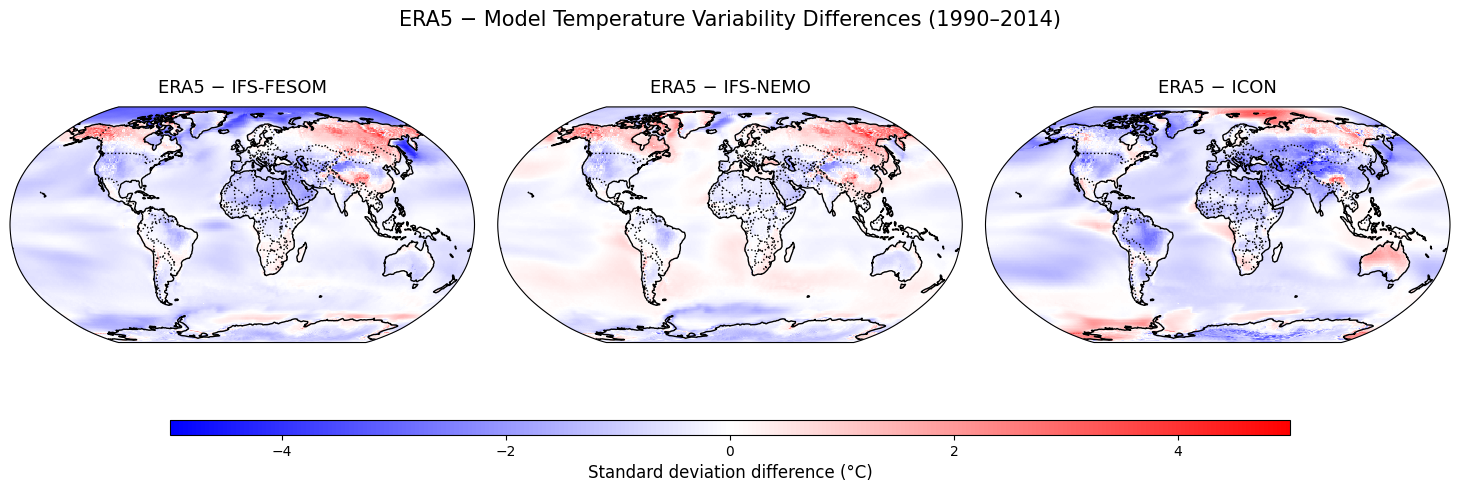

In [4]:
# --------------------------------------------------------
# Plot ERA5 − Model std differences on a Robinson projection
# Side-by-side: IFS-FESOM, IFS-NEMO, ICON (closer layout)
# --------------------------------------------------------
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Prepare difference maps and titles
diff_maps = [diff_fesom, diff_nemo, diff_icon]
titles = ["ERA5 − IFS-FESOM", "ERA5 − IFS-NEMO", "ERA5 − ICON"]

# Color map settings
cmap_diff = "bwr"   # diverging: red=ERA5>Model, blue=Model>ERA5
vmax_diff = 5       # adjust based on your std differences
vmin_diff = -vmax_diff

# Create figure with 3 subplots
fig = plt.figure(figsize=(16,5))  # slightly wider, lower height

for i, (diff, title) in enumerate(zip(diff_maps, titles), 1):
    ax = fig.add_subplot(1, 3, i, projection=ccrs.Robinson())
    im = ax.pcolormesh(diff.lon, diff.lat, diff,
                       transform=ccrs.PlateCarree(),
                       cmap=cmap_diff, vmin=vmin_diff, vmax=vmax_diff)
    ax.set_title(title, fontsize=13, pad=10)  # pad reduces distance to plot
    ax.coastlines(resolution='110m')           # high-res coastlines
    ax.add_feature(cfeature.BORDERS, linestyle=':')
    ax.set_global()

# Adjust spacing to bring subplots closer
plt.subplots_adjust(left=0.05, right=0.95, top=0.85, bottom=0.15, wspace=0.05)

# Add single horizontal colorbar below the subplots
cbar_ax = fig.add_axes([0.15, 0.08, 0.7, 0.03])  # [left, bottom, width, height]
cbar = fig.colorbar(im, cax=cbar_ax, orientation="horizontal")
cbar.set_label("Standard deviation difference (°C)", fontsize=12)

plt.suptitle("ERA5 − Model Temperature Variability Differences (1990–2014)", fontsize=15, y=0.93)
plt.show()

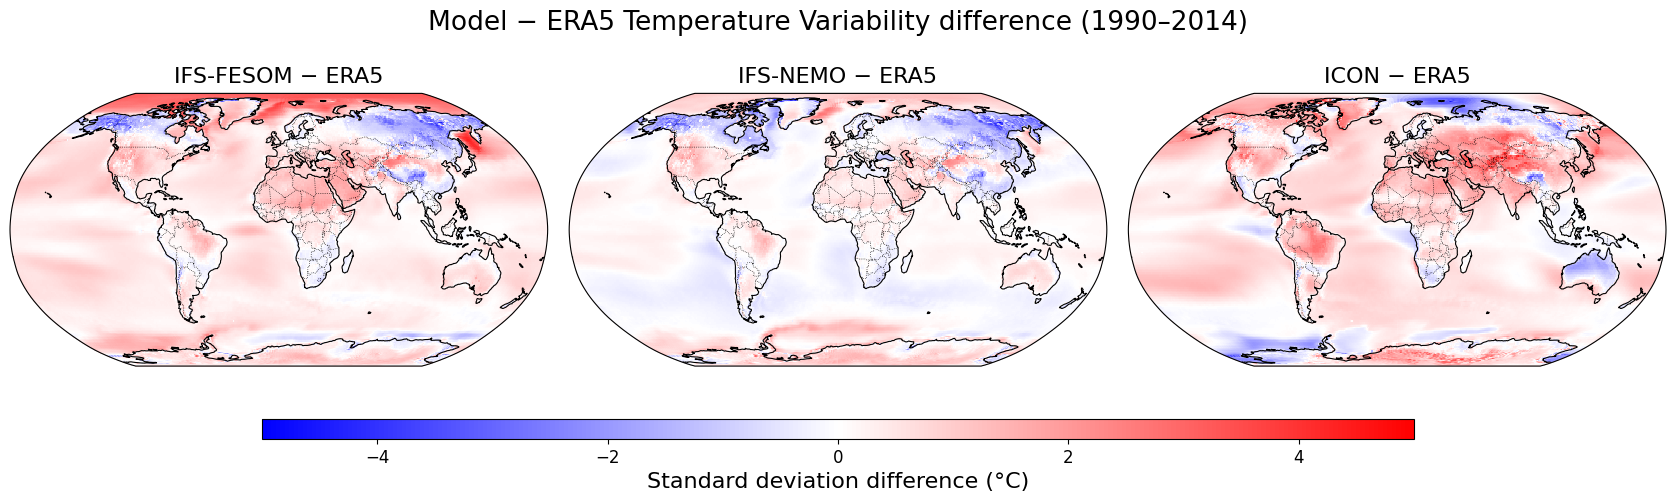

In [10]:
# --------------------------------------------------------
# Plot Model − ERA5 std differences on a Robinson projection
# Side-by-side: IFS-FESOM, IFS-NEMO, ICON (PPT-ready)
# --------------------------------------------------------
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# --------------------------------------------------------
# Compute differences: Model − ERA5
# Positive = Model variability > ERA5
# --------------------------------------------------------
diff_fesom = t2_ifs_fesom_std - t2_era_std
diff_nemo  = t2_ifs_nemo_std  - t2_era_std
diff_icon  = t2_icon_std      - t2_era_std

diff_maps = [diff_fesom, diff_nemo, diff_icon]
titles = ["IFS-FESOM − ERA5", "IFS-NEMO − ERA5", "ICON − ERA5"]

# --------------------------------------------------------
# Color settings
# --------------------------------------------------------
cmap_diff = "bwr"   # diverging
vmax_diff = 5       # symmetric limits
vmin_diff = -vmax_diff

# --------------------------------------------------------
# Create figure
# --------------------------------------------------------
fig = plt.figure(figsize=(18, 5.5))  # wider & taller for PPT

for i, (diff, title) in enumerate(zip(diff_maps, titles), 1):
    ax = fig.add_subplot(1, 3, i, projection=ccrs.Robinson())
    
    im = ax.pcolormesh(
        diff.lon, diff.lat, diff,
        transform=ccrs.PlateCarree(),
        cmap=cmap_diff,
        vmin=vmin_diff,
        vmax=vmax_diff
    )
    
    ax.set_title(title, fontsize=16, pad=8)
    ax.coastlines(resolution="110m", linewidth=0.8)
    ax.add_feature(cfeature.BORDERS, linestyle=":", linewidth=0.5)
    ax.set_global()

# --------------------------------------------------------
# Layout tuning (closer panels, room for colorbar)
# --------------------------------------------------------
plt.subplots_adjust(
    left=0.04,
    right=0.96,
    top=0.82,
    bottom=0.18,
    wspace=0.04
)

# --------------------------------------------------------
# Colorbar (moved upward)
# --------------------------------------------------------
cbar_ax = fig.add_axes([0.18, 0.12, 0.64, 0.035])  # higher than before
cbar = fig.colorbar(im, cax=cbar_ax, orientation="horizontal")
cbar.set_label(
    "Standard deviation difference (°C)",
    fontsize=16
)
cbar.ax.tick_params(labelsize=12)

# --------------------------------------------------------
# Suptitle
# --------------------------------------------------------
plt.suptitle(
    "Model − ERA5 Temperature Variability difference (1990–2014)",
    fontsize=19,
    y=0.90
)

plt.show()

## Remove Seasonal cycle

In [1]:
# Step 1: Load the temperature files (1990–2014, in °C) and regrid ERA5 to model grid
import xarray as xr
import numpy as np

# File paths
file_fesom = f"{EVA_DIR}/IFS-FESOM_t2m_1990_2014_degC.nc"
file_nemo  = f"{EVA_DIR}/IFS-NEMO_t2m_1990_2014_degC.nc"
file_icon  = f"{EVA_DIR}/ICON_t2m_1990_2014_degC.nc"
file_era   = f"{EVA_DIR}/ERA5_t2m_1990_2014_degC.nc"

# Load DataArrays
t2_ifs_fesom = xr.open_dataarray(file_fesom)
t2_ifs_nemo  = xr.open_dataarray(file_nemo)
t2_icon      = xr.open_dataarray(file_icon)
t2_era       = xr.open_dataarray(file_era)

# Check shapes and coordinates
print("IFS-FESOM:", t2_ifs_fesom.shape, t2_ifs_fesom.dims)
print("IFS-NEMO :", t2_ifs_nemo.shape, t2_ifs_nemo.dims)
print("ICON     :", t2_icon.shape, t2_icon.dims)
print("ERA5     :", t2_era.shape, t2_era.dims)

IFS-FESOM: (300, 180, 360) ('time', 'lat', 'lon')
IFS-NEMO : (300, 180, 360) ('time', 'lat', 'lon')
ICON     : (300, 180, 360) ('time', 'lat', 'lon')
ERA5     : (300, 721, 1440) ('time', 'lat', 'lon')


In [2]:
# Step 2: Check time coordinate consistency and type

print("Time dtype (IFS-FESOM):", t2_ifs_fesom.time.dtype)
print("Time dtype (ERA5):", t2_era.time.dtype)

print("First / last time (IFS-FESOM):", 
      t2_ifs_fesom.time.values[0], t2_ifs_fesom.time.values[-1])

print("First / last time (ERA5):", 
      t2_era.time.values[0], t2_era.time.values[-1])

print("Time length equal:",
      len(t2_ifs_fesom.time) == len(t2_era.time))

Time dtype (IFS-FESOM): datetime64[ns]
Time dtype (ERA5): datetime64[ns]
First / last time (IFS-FESOM): 1990-01-01T00:00:00.000000000 2014-12-01T00:00:00.000000000
First / last time (ERA5): 1990-01-01T12:00:00.000000000 2014-12-01T12:00:00.000000000
Time length equal: True


In [3]:
# Step 3: Verify that all model grids are identical

print("Model lat identical (FESOM vs NEMO):",
      np.array_equal(t2_ifs_fesom.lat, t2_ifs_nemo.lat))

print("Model lon identical (FESOM vs NEMO):",
      np.array_equal(t2_ifs_fesom.lon, t2_ifs_nemo.lon))

print("Model lat identical (FESOM vs ICON):",
      np.array_equal(t2_ifs_fesom.lat, t2_icon.lat))

print("Model lon identical (FESOM vs ICON):",
      np.array_equal(t2_ifs_fesom.lon, t2_icon.lon))

Model lat identical (FESOM vs NEMO): True
Model lon identical (FESOM vs NEMO): True
Model lat identical (FESOM vs ICON): True
Model lon identical (FESOM vs ICON): True


In [4]:
# Step 4: Inspect ERA5 latitude and longitude orientation

print("ERA5 lat min/max:", float(t2_era.lat.min()), float(t2_era.lat.max()))
print("ERA5 lon min/max:", float(t2_era.lon.min()), float(t2_era.lon.max()))

print("ERA5 lat increasing:",
      np.all(np.diff(t2_era.lat.values) > 0))

print("ERA5 lon increasing:",
      np.all(np.diff(t2_era.lon.values) > 0))

ERA5 lat min/max: -90.0 90.0
ERA5 lon min/max: -180.0 179.75
ERA5 lat increasing: True
ERA5 lon increasing: True


In [5]:
# Step 6: Check if NaN mask is time-invariant (critical for detrending)

def time_invariant_mask(da, name):
    mask_t0 = np.isnan(da.isel(time=0))
    mask_all = np.isnan(da).any(dim="time")
    identical = np.array_equal(mask_t0, mask_all)
    print(f"{name}: Time-invariant NaN mask =", identical)

time_invariant_mask(t2_ifs_fesom, "IFS-FESOM")
time_invariant_mask(t2_ifs_nemo,  "IFS-NEMO")
time_invariant_mask(t2_icon,      "ICON")
time_invariant_mask(t2_era,       "ERA5")

IFS-FESOM: Time-invariant NaN mask = True
IFS-NEMO: Time-invariant NaN mask = True
ICON: Time-invariant NaN mask = True
ERA5: Time-invariant NaN mask = True


In [6]:
# --------------------------------------------------------
# Step 7: Remove seasonal cycle (monthly climatology)
# Result: monthly temperature anomalies
# --------------------------------------------------------

def deseasonalize(da):
    """
    Remove mean seasonal cycle (monthly climatology) at each grid point.
    """
    clim = da.groupby("time.month").mean("time")
    da_anom = da.groupby("time.month") - clim
    return da_anom

# Apply to all datasets
t2_ifs_fesom_anom = deseasonalize(t2_ifs_fesom)
t2_ifs_nemo_anom  = deseasonalize(t2_ifs_nemo)
t2_icon_anom      = deseasonalize(t2_icon)
t2_era_anom       = deseasonalize(t2_era)

In [7]:
print("Seasonal-cycle removed check (mean over time):")
print("IFS-FESOM:", float(t2_ifs_fesom_anom.mean()))
print("ERA5:", float(t2_era_anom.mean()))

Seasonal-cycle removed check (mean over time):
IFS-FESOM: -3.119370331312242e-17
ERA5: -4.487888247695082e-07


In [7]:
# --------------------------------------------------------
# Step 7: Detrend seasonally adjusted temperature anomalies
# Purpose:
#   • Remove long-term linear trend at each grid point
#   • Retain only internal / interannual variability
# --------------------------------------------------------

from scipy.signal import detrend

def detrend_xr(da):
    """
    Detrend along time dimension at each (lat, lon).
    Assumes:
      - No NaNs
      - Time-invariant mask
      - Seasonal cycle already removed
    """
    return xr.apply_ufunc(
        detrend,
        da,
        input_core_dims=[["time"]],
        output_core_dims=[["time"]],
        vectorize=True,
        dask="parallelized",
        kwargs={"axis": -1, "type": "linear"},
        output_dtypes=[da.dtype],
    )

# Apply detrending
t2_ifs_fesom_dt = detrend_xr(t2_ifs_fesom_anom)
t2_ifs_nemo_dt  = detrend_xr(t2_ifs_nemo_anom)
t2_icon_dt      = detrend_xr(t2_icon_anom)
t2_era_dt       = detrend_xr(t2_era_anom)

In [8]:
print("IFS-FESOM detrended mean:", float(t2_ifs_fesom_dt.mean()))
print("ERA5 detrended mean:", float(t2_era_dt.mean()))

IFS-FESOM detrended mean: 1.8622579473006305e-16
ERA5 detrended mean: -3.629744282918068e-09


In [9]:
# --------------------------------------------------------
# Step 8: Compute temporal standard deviation of detrended
#          and de-seasonalised 2 m temperature
#
# What we do:
#   • Use anomalies after removing the seasonal cycle
#   • Remove the linear trend at each grid point
#   • Compute std over time → interannual variability
#
# Result:
#   • One (lat, lon) map per dataset
#   • Units: °C
# --------------------------------------------------------

# Temporal standard deviation (variability)
t2_ifs_fesom_std = t2_ifs_fesom_dt.std(dim="time")
t2_ifs_nemo_std  = t2_ifs_nemo_dt.std(dim="time")
t2_icon_std      = t2_icon_dt.std(dim="time")
t2_era_std       = t2_era_dt.std(dim="time")

# --------------------------------------------------------
# Sanity checks
# Expected:
#   • No NaNs
#   • Std values ~0–6 °C globally
#   • ERA5 and models of comparable magnitude
# --------------------------------------------------------

print("IFS-FESOM std:")
print("  min / max :", 
      float(t2_ifs_fesom_std.min()),
      float(t2_ifs_fesom_std.max()))
print("  mean      :", float(t2_ifs_fesom_std.mean()))
print("  NaNs      :", int(t2_ifs_fesom_std.isnull().sum()))

print("\nERA5 std:")
print("  min / max :", 
      float(t2_era_std.min()),
      float(t2_era_std.max()))
print("  mean      :", float(t2_era_std.mean()))
print("  NaNs      :", int(t2_era_std.isnull().sum()))

IFS-FESOM std:
  min / max : 0.25260531589303425 5.249708940828348
  mean      : 1.468094605675603
  NaNs      : 0

ERA5 std:
  min / max : 0.20215293765068054 4.699392795562744
  mean      : 1.301942229270935
  NaNs      : 0


In [11]:
# --------------------------------------------------------
# Step 9: Regrid ERA5 std to the model grid
# Purpose:
#   • Bring ERA5 variability onto the model grid
#   • Ensure 1-to-1 spatial comparability
# --------------------------------------------------------
import xarray as xr
import numpy as np

# Use IFS-FESOM grid as reference (common to all models)
target_lat = t2_ifs_fesom_std.lat
target_lon = t2_ifs_fesom_std.lon

# Regrid ERA5 std using bilinear interpolation
t2_era_std_regrid = t2_era_std.interp(
    lat=target_lat,
    lon=target_lon,
    method="linear"
)

# --------------------------------------------------------
# Sanity checks
# --------------------------------------------------------
print("ERA5 std (regridded):")
print("  shape    :", t2_era_std_regrid.shape)
print("  lat match:", np.array_equal(t2_era_std_regrid.lat, target_lat))
print("  lon match:", np.array_equal(t2_era_std_regrid.lon, target_lon))
print("  min/max  :",
      float(t2_era_std_regrid.min()),
      float(t2_era_std_regrid.max()))
print("  mean     :", float(t2_era_std_regrid.mean()))
print("  NaNs     :", int(t2_era_std_regrid.isnull().sum()))

ERA5 std (regridded):
  shape    : (180, 360)
  lat match: True
  lon match: True
  min/max  : 0.20523126423358917 4.054927349090576
  mean     : 1.3514313964384757
  NaNs     : 32400


In [12]:
# =========================================================
# Step 12: Fix ERA5 longitude and regrid std field to model grid
# Purpose:
#   • Convert ERA5 lon from [-180, 180] → [0, 360] to match model grids
#   • Interpolate ERA5 std field (already detrended + deseasonalised)
#     to IFS-FESOM / model grid
#   • Avoid NaNs / half-globe plotting issues
# =========================================================
import xarray as xr
import numpy as np

# -----------------------------
# 12a: Fix longitude
# -----------------------------
t2_era_std_fixlon = t2_era_std.assign_coords(
    lon=(t2_era_std.lon % 360)
).sortby("lon")

# Sanity check for longitude
print("ERA5 lon min/max after fix:",
      float(t2_era_std_fixlon.lon.min()),
      float(t2_era_std_fixlon.lon.max()))

# -----------------------------
# 12b: Regrid ERA5 std to model grid
# -----------------------------
t2_era_std_regrid = t2_era_std_fixlon.interp(
    lat=t2_ifs_fesom_std.lat,
    lon=t2_ifs_fesom_std.lon,
    method="linear"
)

# -----------------------------
# Final sanity check
# -----------------------------
print("ERA5 regridded std:")
print("  shape     :", t2_era_std_regrid.shape)
print("  min / max :", float(t2_era_std_regrid.min()),
                     float(t2_era_std_regrid.max()))
print("  mean      :", float(t2_era_std_regrid.mean()))
print("  NaNs      :", int(np.isnan(t2_era_std_regrid.values).sum()))

ERA5 lon min/max after fix: 0.0 359.75
ERA5 regridded std:
  shape     : (180, 360)
  min / max : 0.20523126423358917 4.699392795562744
  mean      : 1.3006036364894222
  NaNs      : 0


In [13]:
# --------------------------------------------------------
# Save detrended & deseasonalized std data to NetCDF
# --------------------------------------------------------
import xarray as xr

# Create a Dataset from your DataArrays
ds_std = xr.Dataset(
    {
        "IFS_FESOM_std": t2_ifs_fesom_std,
        "IFS_NEMO_std" : t2_ifs_nemo_std,
        "ICON_std"     : t2_icon_std,
        "ERA5_std"     : t2_era_std_regrid
    }
)

# Add global attributes
ds_std.attrs["description"] = (
    "Spatial standard deviation of 2m temperature (1990-2014) "
    "after removing linear trend and seasonal cycle."
)
ds_std.attrs["units"] = "°C"
ds_std.attrs["source_models"] = "IFS-FESOM, IFS-NEMO, ICON"
ds_std.attrs["reference_dataset"] = "ERA5 regridded to model grid"

# Add variable-specific metadata
ds_std["IFS_FESOM_std"].attrs["long_name"] = "IFS-FESOM temperature standard deviation"
ds_std["IFS_NEMO_std"].attrs["long_name"]  = "IFS-NEMO temperature standard deviation"
ds_std["ICON_std"].attrs["long_name"]      = "ICON temperature standard deviation"
ds_std["ERA5_std"].attrs["long_name"]      = "ERA5 temperature standard deviation (regridded)"

ds_std["IFS_FESOM_std"].attrs["units"] = "°C"
ds_std["IFS_NEMO_std"].attrs["units"]  = "°C"
ds_std["ICON_std"].attrs["units"]      = "°C"
ds_std["ERA5_std"].attrs["units"]      = "°C"

# Save to NetCDF
output_file = f"{EVA_DIR}/Temp_std_detrended_1990_2014.nc"
ds_std.to_netcdf(output_file)

print(f"Saved processed std data to {output_file}")

Saved processed std data to <EVA_DIR>/Temp_std_detrended_1990_2014.nc


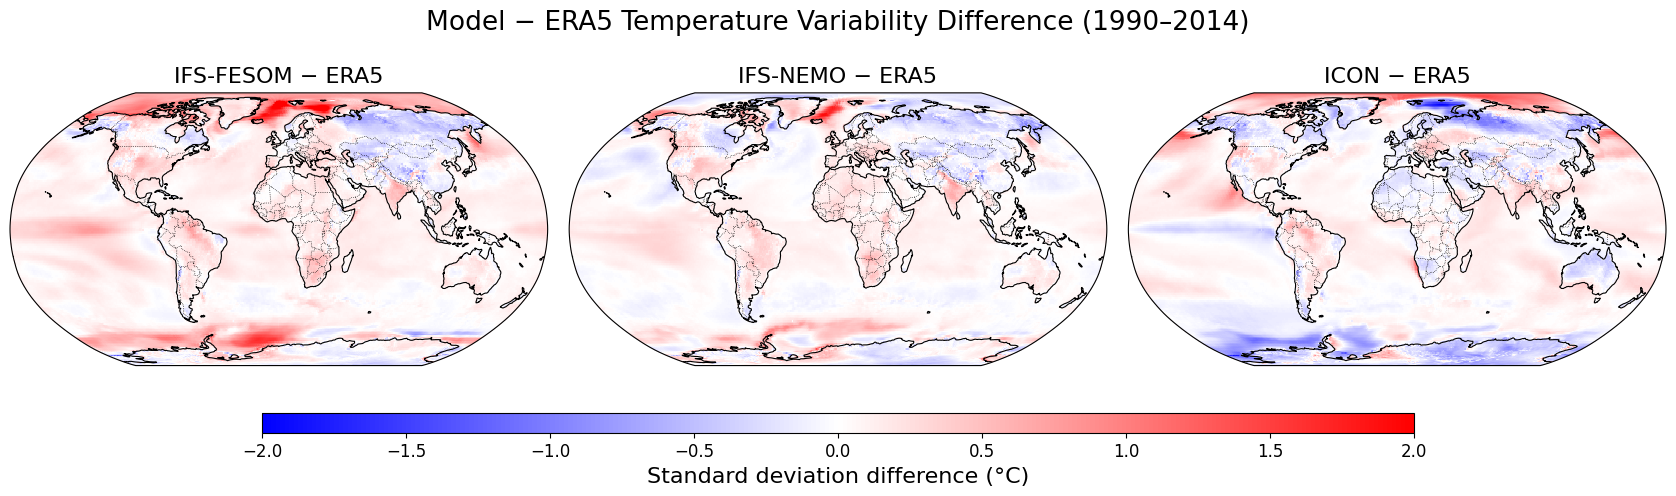

In [17]:
# =========================================================
# Plot Model − ERA5 std differences on a Robinson projection
# Side-by-side: IFS-FESOM, IFS-NEMO, ICON (PPT-ready)
# =========================================================
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# --------------------------------------------------------
# Compute differences: Model − ERA5
# Positive = Model variability > ERA5
# Use regridded ERA5 std
# --------------------------------------------------------
diff_fesom = t2_ifs_fesom_std - t2_era_std_regrid
diff_nemo  = t2_ifs_nemo_std  - t2_era_std_regrid
diff_icon  = t2_icon_std      - t2_era_std_regrid

diff_maps = [diff_fesom, diff_nemo, diff_icon]
titles = ["IFS-FESOM − ERA5", "IFS-NEMO − ERA5", "ICON − ERA5"]

# --------------------------------------------------------
# Color settings
# --------------------------------------------------------
cmap_diff = "bwr"   # diverging
vmax_diff = 2       # symmetric limits
vmin_diff = -vmax_diff

# --------------------------------------------------------
# Create figure
# --------------------------------------------------------
fig = plt.figure(figsize=(18, 5.5))  # wider & taller for PPT

for i, (diff, title) in enumerate(zip(diff_maps, titles), 1):
    ax = fig.add_subplot(1, 3, i, projection=ccrs.Robinson())
    
    im = ax.pcolormesh(
        diff.lon, diff.lat, diff,
        transform=ccrs.PlateCarree(),
        cmap=cmap_diff,
        vmin=vmin_diff,
        vmax=vmax_diff
    )
    
    ax.set_title(title, fontsize=16, pad=8)
    ax.coastlines(resolution="110m", linewidth=0.8)
    ax.add_feature(cfeature.BORDERS, linestyle=":", linewidth=0.5)
    ax.set_global()

# --------------------------------------------------------
# Layout tuning (closer panels, room for colorbar)
# --------------------------------------------------------
plt.subplots_adjust(
    left=0.04,
    right=0.96,
    top=0.82,
    bottom=0.18,
    wspace=0.04
)

# --------------------------------------------------------
# Colorbar (slightly higher)
# --------------------------------------------------------
cbar_ax = fig.add_axes([0.18, 0.13, 0.64, 0.035])  # move upward for PPT
cbar = fig.colorbar(im, cax=cbar_ax, orientation="horizontal")
cbar.set_label(
    "Standard deviation difference (°C)",
    fontsize=16
)
cbar.ax.tick_params(labelsize=12)

# --------------------------------------------------------
# Suptitle
# --------------------------------------------------------
plt.suptitle(
    "Model − ERA5 Temperature Variability Difference (1990–2014)",
    fontsize=19,
    y=0.90
)

plt.show()

## Overlapping plots

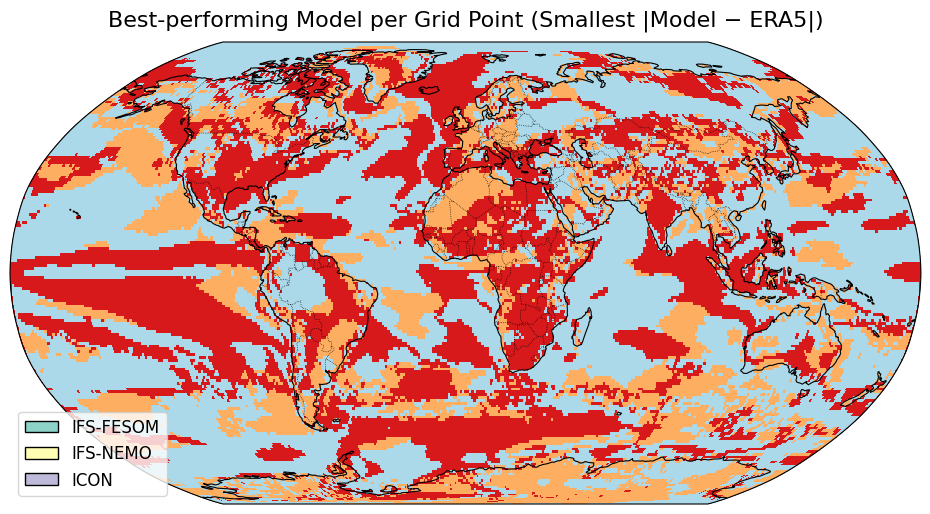

In [3]:
# --------------------------------------------------------
# Map showing the best-performing model per grid point
# Based on smallest absolute Model − ERA5 difference
# --------------------------------------------------------
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import xarray as xr
from matplotlib.patches import Patch

# --------------------------------------------------------
# Step 1: Load processed std data
# --------------------------------------------------------
file_std = f"{EVA_DIR}/Temp_std_detrended_1990_2014.nc"
ds_std = xr.open_dataset(file_std)

t2_ifs_fesom_std = ds_std["IFS_FESOM_std"]
t2_ifs_nemo_std  = ds_std["IFS_NEMO_std"]
t2_icon_std      = ds_std["ICON_std"]
t2_era_std       = ds_std["ERA5_std"]

# --------------------------------------------------------
# Step 2: Compute absolute differences (Model − ERA5)
# --------------------------------------------------------
diff_fesom = t2_ifs_fesom_std - t2_era_std
diff_nemo  = t2_ifs_nemo_std  - t2_era_std
diff_icon  = t2_icon_std      - t2_era_std

abs_fesom = np.abs(diff_fesom)
abs_nemo  = np.abs(diff_nemo)
abs_icon  = np.abs(diff_icon)

# --------------------------------------------------------
# Step 3: Combine into single array and find the best model
# --------------------------------------------------------
combined = xr.concat([abs_fesom, abs_nemo, abs_icon], dim="model")
combined = combined.assign_coords(model=["IFS-FESOM", "IFS-NEMO", "ICON"])

# Index of model with minimum difference at each grid point
best_model_idx = combined.argmin(dim="model")  # 0=FESOM, 1=NEMO, 2=ICON

# --------------------------------------------------------
# Step 4: Define discrete colormap
# --------------------------------------------------------
#cmap = mcolors.ListedColormap(["light blue", "light green", "light orange"])
cmap = mcolors.ListedColormap(["#8dd3c7", "#ffffb3", "#bebada"])  # IFS-FESOM = teal-ish, IFS-NEMO = pale yellow, ICON = lavender
bounds = [-0.5, 0.5, 1.5, 2.5]
norm = mcolors.BoundaryNorm(bounds, cmap.N)

# --------------------------------------------------------
# Step 5: Plotting
# --------------------------------------------------------
fig = plt.figure(figsize=(12, 6))
ax = plt.axes(projection=ccrs.Robinson())

im = ax.pcolormesh(
    t2_ifs_fesom_std.lon, t2_ifs_fesom_std.lat, best_model_idx,
    transform=ccrs.PlateCarree(),
    cmap=cmap, norm=norm
)

ax.coastlines(resolution="110m", linewidth=0.8)
ax.add_feature(cfeature.BORDERS, linestyle=":", linewidth=0.5)
ax.set_global()

# --------------------------------------------------------
# Step 6: Colorbar / Legend
# --------------------------------------------------------
# legend_elements = [
#     Patch(facecolor="blue",  edgecolor='k', label="IFS-FESOM"),
#     Patch(facecolor="green", edgecolor='k', label="IFS-NEMO"),
#     Patch(facecolor="yellow",edgecolor='k', label="ICON")
# ]

legend_elements = [
    Patch(facecolor="#8dd3c7", edgecolor='k', label="IFS-FESOM"),  # teal-ish
    Patch(facecolor="#ffffb3", edgecolor='k', label="IFS-NEMO"),   # pale yellow
    Patch(facecolor="#bebada", edgecolor='k', label="ICON")        # lavender
]

ax.legend(handles=legend_elements, loc="lower left", fontsize=12, frameon=True)
ax.legend(handles=legend_elements, loc="lower left", fontsize=12, frameon=True)

# --------------------------------------------------------
# Step 7: Title
# --------------------------------------------------------
plt.title(
    "Best-performing Model per Grid Point (Smallest |Model − ERA5|)",
    fontsize=16, pad=12
)

plt.show()

## Zonal variability

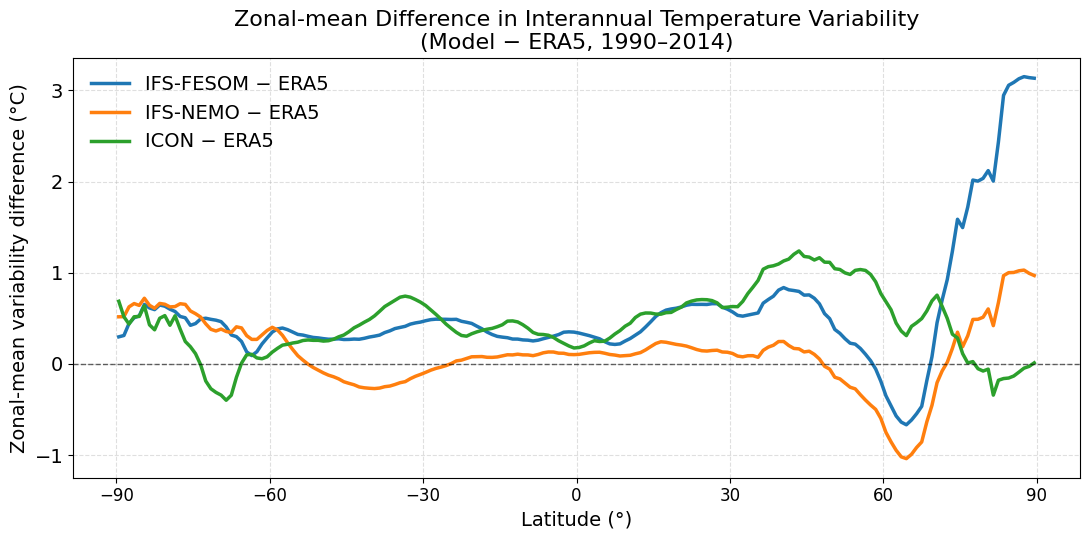

In [12]:
# --------------------------------------------------------
# Zonal-mean variability comparison (Model − ERA5)
# Positive = Model variability > ERA5
# --------------------------------------------------------
import matplotlib.pyplot as plt
import numpy as np

# Compute differences: Model − ERA5
# Positive = Model variability > ERA5
# --------------------------------------------------------
diff_fesom = t2_ifs_fesom_std - t2_era_std
diff_nemo  = t2_ifs_nemo_std  - t2_era_std
diff_icon  = t2_icon_std      - t2_era_std
# --------------------------------------------------------
# Compute zonal mean (mean over longitude)
# diff_* already defined as: Model_std − ERA5_std
# --------------------------------------------------------
diff_fesom_zonal = diff_fesom.mean(dim="lon")
diff_nemo_zonal  = diff_nemo.mean(dim="lon")
diff_icon_zonal  = diff_icon.mean(dim="lon")

# Latitude (shared grid)
lat = diff_fesom.lat

# --------------------------------------------------------
# Plot
# --------------------------------------------------------
plt.figure(figsize=(11, 5.5))  # PPT-friendly aspect ratio

plt.plot(
    lat, diff_fesom_zonal,
    label="IFS-FESOM − ERA5",
    linewidth=2.5
)
plt.plot(
    lat, diff_nemo_zonal,
    label="IFS-NEMO − ERA5",
    linewidth=2.5
)
plt.plot(
    lat, diff_icon_zonal,
    label="ICON − ERA5",
    linewidth=2.5
)

# --------------------------------------------------------
# Axes, labels, ticks
# --------------------------------------------------------
plt.xlabel("Latitude (°)", fontsize=14)
plt.ylabel("Zonal-mean variability difference (°C)", fontsize=14)
plt.title(
    "Zonal-mean Difference in Interannual Temperature Variability\n(Model − ERA5, 1990–2014)",
    fontsize=16
)

plt.xticks(np.arange(-90, 91, 30), fontsize=12)
plt.yticks(fontsize=14)

plt.axhline(0, color="k", linewidth=1, linestyle="--", alpha=0.6)

plt.grid(True, linestyle="--", alpha=0.4)
plt.legend(fontsize=14, frameon=False)

plt.tight_layout()
plt.show()

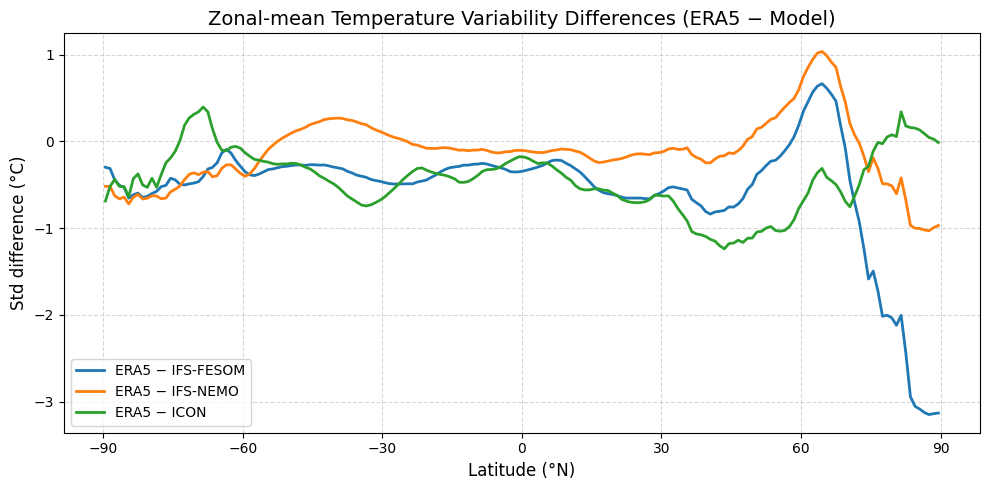

In [35]:
# --------------------------------------------------------
# Zonal-mean variability comparison (ERA5 − Models)
# --------------------------------------------------------
import matplotlib.pyplot as plt
import numpy as np

# Compute zonal mean (mean over longitude)
# Note: diff_maps already = ERA5_std_regrid - model_std
diff_fesom_zonal = diff_fesom.mean(dim="lon")
diff_nemo_zonal  = diff_nemo.mean(dim="lon")
diff_icon_zonal  = diff_icon.mean(dim="lon")

# Latitude for x-axis
lat = diff_fesom.lat  # same for all models

# Plotting
plt.figure(figsize=(10,5))

plt.plot(lat, diff_fesom_zonal, label="ERA5 − IFS-FESOM", color="C0", linewidth=2)
plt.plot(lat, diff_nemo_zonal,  label="ERA5 − IFS-NEMO",  color="C1", linewidth=2)
plt.plot(lat, diff_icon_zonal,  label="ERA5 − ICON",      color="C2", linewidth=2)

plt.xlabel("Latitude (°N)", fontsize=12)
plt.ylabel("Std difference (°C)", fontsize=12)
plt.title("Zonal-mean Temperature Variability Differences (ERA5 − Model)", fontsize=14)
plt.xticks(np.arange(-90, 91, 30))  # x-axis ticks: -90 -60 -30 0 30 60 90
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

# Error